# Fleet-relative condition monitoring: Penmanshiel

Six steps, each building on the last:

1. **Cleaning and healthy reference**: flag non-normal operation from the status log and SCADA, then choose the time split
2. **Normal-behaviour residuals**: per-turbine models of component temperatures
3. **PCA**: on raw signals and on residuals, with SPE / T² alarms
4. **Grouping turbines**: four clustering methods, compared with the farm layout
5. **Fleet-relative drift**: peer residuals, CUSUM / Page-Hinkley, change points, alignment with events
6. **Injected-fault validation**: detection rate, delay and false alarms of five detectors

Data comes from `penmanshiel_process.py` (see `eda_penmanshiel.ipynb`). The reusable parts are in `penmanshiel.py` (loading, flags, healthy mask) and `detectors.py` (PCA monitor, persistence, CUSUM, Page-Hinkley, step/ramp classification). All tunable settings are in the next cell.

The Gaussian-process population form (Bull et al. 2021) with its interactive explorer is in `population_form_penmanshiel.ipynb`, which reads this notebook's saved residuals and flags.

In [1]:
import hashlib
import json
import time
from pathlib import Path

import igraph as ig
import leidenalg
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import ruptures as rpt
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

import penmanshiel as pm
from detectors import PCAMonitor, alarm_onsets, classify_change, cusum, page_hinkley, persistence

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

In [2]:
# ------------------------------------------------------------------ configuration
# Time split. Proposed default (see Step 1 for why it differs from 2016-17 / 2018-19 / 2020+):
SPLIT = {
    "reference": ("2018-06-01", "2019-06-01"),   # fit PCA, thresholds and groups
    "training":  ("2019-06-01", "2020-06-01"),   # fit normal-behaviour models
    "test":      ("2020-06-01", "2024-01-01"),   # evaluate
}
# SPLIT = {"reference": ("2016-09-01", "2018-01-01"), "training": ("2018-01-01", "2020-01-01"),
#          "test": ("2020-01-01", "2024-01-01")}   # the originally requested split (no gearbox temps in reference)

# Flags that make a sample non-healthy. Every flag is kept as a column, so drop names here to relax the mask.
HEALTHY_EXCLUDE = ["stop", "warning", "power_reduced", "curtailment", "communication", "forced_outage",
                   "maintenance", "derate", "requested_shutdown", "technical_standby", "electrical_spec",
                   "post_event", "commissioning", "not_running", "derate_setpoint", "missing", "out_of_range"]
POST_EVENT = pd.Timedelta("2h")          # settle time after stops / outages / maintenance

# Normal-behaviour model
INPUTS = ["wind_speed", "power", "power_1h", "rotor_speed", "nacelle_ambient_temperature", "nacelle_temperature"]
TARGETS = ["front_bearing_temperature", "rear_bearing_temperature", "gear_oil_temperature",
           "gear_oil_inlet_temperature", "generator_bearing_front_temperature",
           "generator_bearing_rear_temperature", "stator_temperature_1", "rotor_bearing_temp"]
NBM = "hgb"                              # "hgb" (gradient boosting) or "ridge" (splines + ridge)

# PCA monitoring
RAW_SIGNALS = ["wind_speed", "power", "rotor_speed", "blade_angle_pitch_position_a",
               "nacelle_ambient_temperature", "nacelle_temperature", *TARGETS]
VAR_EXPLAINED = 0.90                     # components kept
PERCENTILE = 99.0                        # SPE / T2 threshold on reference data
N_CONSECUTIVE = 6                        # persistence: alarm after N consecutive exceedances (6 = 1 hour)
WIND_BINS = [3, 6, 9, 12, 40]            # m/s, for the per-bin PCA variant and the daily aggregation

# Grouping
K_GRAPH = 3                              # neighbours in the kNN graph
K_PEERS = 4                              # peers per turbine for peer residuals
GROUP_METHOD = "hierarchical"            # which method's groups to freeze

# Drift
MIN_BIN_COUNT = 6                        # samples needed in a wind bin for a daily value
CUSUM_K = 0.5                            # reference in reference SDs
PH_DELTA = 0.5
SERIES_FA_TARGET = 1 / 12                # calibrate CUSUM h / Page-Hinkley lambda to this many false alarms
                                         # per turbine-target-month on reference data (about one per year)
CAL_GRID = np.arange(3, 80.5, 0.5)       # candidate h / lambda values
PELT_PENALTY = 25.0
ALIGN_DAYS = 14                          # change point "matches" an event within this many days
N_SHUFFLE = 500

# Injection
INJECT_TARGET = "front_bearing_temperature"
INJECT_SIZES = [1.0, 2.0, 3.0, 5.0]      # deg C
RAMP_DAYS = 30                           # ramp reaches full size after this many days
ONSETS = ["2021-03-01", "2021-10-01", "2022-05-01"]
HORIZON_DAYS = 90
TARGET_FA = 0.25                         # Step 6: every detector calibrated to this many false alarms per
                                         # turbine-month on reference data, so they are compared at equal cost
SPE_PCT_GRID = [99.0, 99.5, 99.8, 99.9, 99.95, 99.98, 99.99, 99.995, 99.999]

OUT = pm.DATA_DIR / "analysis"
OUT.mkdir(exist_ok=True)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e6e5e0", "#b5b4ad"
LBL = pm.SIGNAL_LABELS | {"power_1h": "Active power, 1 h mean"}


def style_ax(ax, grid_axis="both"):
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.title.set_color(INK)

## Step 1: Cleaning and healthy reference

### Load
All 14 turbines, the signals used below, plus the status log. Values are stored as float32 (about 400 MB in memory).

In [3]:
turbines = pm.load_turbines()
TURBINES = turbines["turbine_id"].tolist()
TL = {t: f"T{t:02d}" for t in TURBINES}
scada = pm.load_scada(TURBINES, [*pm.SIGNAL_LABELS, "wind_direction"])
status = pm.load_status(TURBINES)
# 1-hour mean power: component temperatures lag the load, so this is a strong extra input.
scada["power_1h"] = (scada.set_index("time_stamp").groupby("turbine_id")["power"]
                     .rolling("1h").mean().to_numpy().astype("float32"))
print(f"{len(scada):,} rows x {scada.shape[1]} columns, {scada.memory_usage().sum() / 1e6:.0f} MB")

5,495,456 rows x 20 columns, 445 MB


### Flags

**From the status log**: every timed event marks the 10-minute slots it overlaps.

| flag | rule |
|---|---|
| `stop` | status = Stop |
| `warning` | status = Warning, excluding the codes below |
| `power_reduced` | warnings 9000 *P output externally reduced*, 3220 *Reduced power converter* |
| `warning_benign` | obstacle light, clock sync, comms, control-box heaters, pitch battery charge (not excluded by default) |
| `curtailment`, `communication` | status of that name |
| `forced_outage`, `derate`, `requested_shutdown`, `technical_standby`, `electrical_spec` | IEC category |
| `maintenance` | IEC *Scheduled Maintenance* or *Manual stop (service)* |
| `post_event` | 2 h after a stop, outage, maintenance or requested shutdown (temperatures settling) |

**From the SCADA**: `commissioning` (before 2016-09-01); `not_running` (power ≤ 20 kW or rotor ≤ 5 rpm); `derate_setpoint` (setpoint < 95% of rated with wind > 11 m/s); `missing` (a model input or target is NaN); `out_of_range` (outside physical limits, or a temperature of exactly 0 °C, which is a sensor dropout).

Nothing is deleted. `healthy` combines the flags in `HEALTHY_EXCLUDE`.

In [4]:
t0 = time.time()
flags = pd.concat([pm.status_flags(scada, status, post_event=POST_EVENT),
                   pm.scada_flags(scada, required=[c for c in INPUTS if c != "power_1h"] + TARGETS)], axis=1)
healthy = pm.healthy_mask(flags, HEALTHY_EXCLUDE).to_numpy()
period = pm.period_of(scada["time_stamp"], SPLIT)
print(f"flags in {time.time() - t0:.1f} s")

others_any = lambda c: flags[[x for x in HEALTHY_EXCLUDE if x != c]].any(axis=1)
flag_table = pd.DataFrame({
    "% of rows": 100 * flags.mean(),
    "% only this flag": pd.Series({c: 100 * (flags[c] & ~others_any(c)).mean() if c in HEALTHY_EXCLUDE else np.nan
                                   for c in flags}),
    "excluded": pd.Series({c: c in HEALTHY_EXCLUDE for c in flags}),
}).sort_values("% of rows", ascending=False)
flag_table.round(2)

flags in 7.9 s


,% of rows,% only this flag,excluded
missing,26.38,15.48,True
not_running,22.43,11.95,True
warning_benign,8.80,NaN,False
warning,6.89,3.40,True
stop,4.91,0.00,True
post_event,3.42,1.39,True
power_reduced,2.58,0.00,True
commissioning,2.49,0.00,True
communication,2.46,0.02,True
derate,2.38,0.00,True


### Healthy data over time

Share of each turbine-month that is healthy. Before June 2018 nothing qualifies, because the gearbox temperatures (axle bearings, gear oil, gear-oil inlet), pitch angle and power setpoint were not exported until then. Every gearbox-related target is missing.

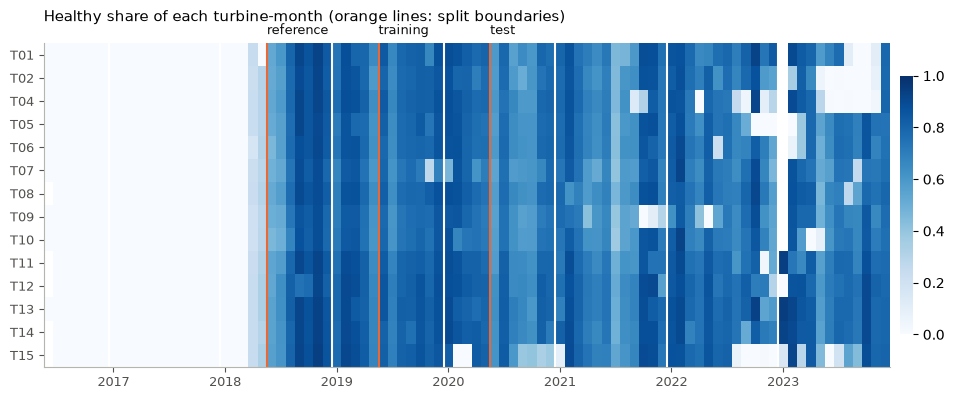

Gearbox bearing temperature availability by year: {2016: 0.0, 2017: 0.0, 2018: 0.66, 2019: 0.99, 2020: 0.94, 2021: 0.99, 2022: 0.98, 2023: 0.99}


col_0,not healthy,healthy
row_0,,
reference,0.23,0.77
training,0.22,0.78
test,0.34,0.66
none,0.98,0.02


In [5]:
month = scada["time_stamp"].dt.to_period("M")
hm = pd.Series(healthy).groupby([scada["turbine_id"], month]).mean().unstack()
gear_avail = scada["front_bearing_temperature"].notna().groupby(month).mean()

fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(hm.to_numpy(float), aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="none")
ax.set_yticks(range(len(hm)), [TL[t] for t in hm.index])
months = hm.columns
ys = [i for i, m in enumerate(months) if m.month == 1]
ax.set_xticks(ys, [months[i].year for i in ys])
for i in ys:
    ax.axvline(i - 0.5, color="white", lw=1.5)
for name, (s, e) in SPLIT.items():
    i0 = max(0, months.searchsorted(pd.Period(s, "M")))
    ax.annotate(name, (i0 - 0.5, -0.9), fontsize=9, color=INK, annotation_clip=False)
    ax.axvline(i0 - 0.5, color=PALETTE[1], lw=1.5)
ax.set_title("Healthy share of each turbine-month (orange lines: split boundaries)", loc="left", fontsize=11, pad=16)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

print("Gearbox bearing temperature availability by year:",
      gear_avail.groupby(gear_avail.index.year).mean().round(2).to_dict())
pd.crosstab(period, healthy, normalize="index").rename(columns={True: "healthy", False: "not healthy"}).round(2)

### The time split: proposed change

The requested split was **reference 2016–2017, training 2018–2019, test 2020 onwards**. Checked against the gaps found in the EDA:

| issue | effect on the requested split | proposal |
|---|---|---|
| Gearbox temperatures, pitch and setpoint only exist from **June 2018** | the reference period has no gearbox bearings at all, so PCA, thresholds and groups could not include them | start the reference period in June 2018 |
| Mid-2016 is commissioning (until 2016-09-01) | partial and abnormal data | (moot once the reference moves) |
| Training 2018 would start with 5 months of missing gearbox data | less training data than it looks | use one full year |
| Farm-wide outage Aug–Sep 2020; no WT01–10 data Jan 2023; T10 out Mar–May 2023 | inside the test period | keep, but avoid these dates for fault injection |
| Drive-train acceleration changes scale in 2018 | none (not used) | none |

**Proposed:** reference = Jun 2018 – May 2019, training = Jun 2019 – May 2020, test = Jun 2020 – Dec 2023. Each of the first two is a full 12-month seasonal cycle with every signal present.

The reference period comes *before* training, as requested. So reference residuals come from a model fitted on later data. They are out-of-sample, which gives realistic thresholds; residuals from the training period itself would be too small. The original split is commented out in the configuration cell.

## Step 2: Normal-behaviour residuals

For each turbine and each component temperature, a model predicts the temperature from wind speed, power, 1-hour mean power, rotor speed, ambient temperature and nacelle temperature. It is fitted on healthy training-period data only, and the residual is actual minus predicted. Residuals are computed for **every** timestamp where the target exists (gradient boosting handles missing inputs). They are saved to `data/Penmanshiel/analysis/residuals.parquet` together with the flags and the healthy mask.

Gradient boosting (`NBM = "hgb"`) is the default; `"ridge"` uses spline features and ridge regression and is about twice as fast. Results are cached under a hash of the settings, so re-running is quick unless something changes.

In [6]:
def make_model():
    if NBM == "hgb":
        return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, random_state=0)
    return make_pipeline(StandardScaler(), SplineTransformer(n_knots=6), RidgeCV())

key = hashlib.md5(json.dumps([SPLIT, HEALTHY_EXCLUDE, str(POST_EVENT), INPUTS, TARGETS, NBM]).encode()).hexdigest()[:8]
cache = OUT / f"residuals_{key}.parquet"
if cache.exists():
    resid = pd.read_parquet(cache, columns=TARGETS)
    print(f"Loaded cached residuals {cache.name}")
else:
    t0 = time.time()
    resid = pd.DataFrame(np.nan, index=scada.index, columns=TARGETS, dtype="float32")
    train = healthy & (period == "training")
    for t in TURBINES:
        rows = (scada["turbine_id"] == t).to_numpy()
        X = scada.loc[rows, INPUTS]
        for y in TARGETS:
            fit_rows = rows & train & scada[y].notna().to_numpy()
            model = make_model().fit(scada.loc[fit_rows, INPUTS], scada.loc[fit_rows, y])
            resid.loc[rows, y] = (scada.loc[rows, y] - model.predict(X)).astype("float32")
    print(f"Fitted {len(TURBINES) * len(TARGETS)} models in {time.time() - t0:.0f} s")
    out = pd.concat([scada[["turbine_id", "time_stamp"]], resid, flags,
                     pd.DataFrame({"healthy": healthy, "period": period}, index=scada.index)], axis=1)
    out.to_parquet(cache, index=False)
    out.to_parquet(OUT / "residuals.parquet", index=False)
    print(f"Saved {cache.name} and residuals.parquet")

Loaded cached residuals residuals_134ee186.parquet


In [7]:
# Residual spread: in-sample (training) vs out-of-sample (reference, test), healthy samples, all turbines.
rows = []
for p in ["training", "reference", "test"]:
    m = healthy & (period == p)
    r = resid[m]
    rows.append(pd.DataFrame({"period": p, "mean": r.mean(), "sd": r.std(), "raw sd": scada.loc[m, TARGETS].std()}))
fit_table = pd.concat(rows).reset_index(names="target")
fit_table["target"] = fit_table["target"].map(LBL)
fit_table.pivot(index="target", columns="period", values=["sd", "mean", "raw sd"]).round(2)

sd                     mean                   raw sd               
period                             reference  test training reference  test training reference  test training
target                                                                                                       
Gearbox bearing 1 (axle bearing 1)      2.36  2.36     1.88     -0.23  0.15     -0.0      6.41  6.38     6.10
Gearbox bearing 2 (axle bearing 2)      2.34  2.74     1.81     -0.25 -0.17     -0.0      5.02  4.83     4.57
Gearbox oil (sump)                      2.62  2.51     1.95     -0.13 -0.12     -0.0      3.95  3.76     3.51
Gearbox oil inlet                       5.88  5.84     5.19     -0.53 -0.03      0.0      8.57  8.29     8.30
Generator bearing, drive end            3.77  3.88     2.13      0.85  0.60     -0.0      5.75  5.87     5.28
Generator bearing, non-drive end        2.44  2.15     1.55      0.56  0.01     -0.0      3.89  3.85     3.70
Generator stator winding                2.70  2.65     2.11      0.01 -0.05     -0.0      7.90  7.75     8.12
Main (rotor) bearing                    2.19  2.37     1.44     -0.03  1.73     -0.0      3.58  3.55     3.63

Residual SD is about 2–2.5 °C for most components, against 3–8 °C for the raw temperatures. Gear-oil inlet is the exception (about 6 °C): it is governed by the oil cooler and thermostat rather than by load, so the inputs explain little. Reference residuals have small non-zero means, because the model is fitted a year later.

### Residual distributions per turbine

Healthy reference-period residuals (out-of-sample). Boxes show the interquartile range and whiskers the 1st–99th percentiles. A box shifted away from zero means that turbine ran warmer or cooler in the reference year than its own model expects.

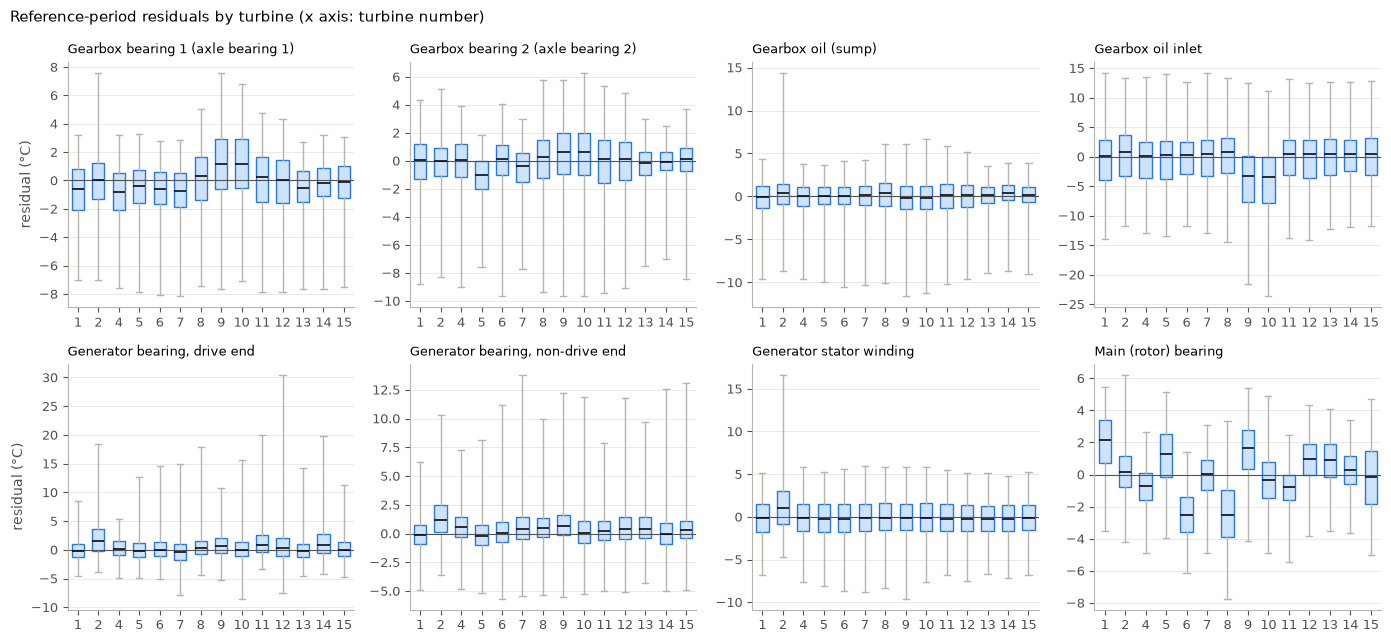

In [8]:
ref_h = healthy & (period == "reference")
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey=False)
for ax, y in zip(axes.flat, TARGETS):
    data = [resid.loc[ref_h & (scada["turbine_id"] == t).to_numpy(), y].dropna().to_numpy() for t in TURBINES]
    bp = ax.boxplot(data, whis=(1, 99), showfliers=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
    for b in bp["boxes"]:
        b.set(facecolor="#cde2fb", edgecolor=PALETTE[0])
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(range(1, len(TURBINES) + 1), [str(t) for t in TURBINES], fontsize=8)
    ax.set_title(LBL[y], loc="left", fontsize=9.5)
    style_ax(ax, grid_axis="y")
for ax in axes[:, 0]:
    ax.set_ylabel("residual (°C)", color=MUTED)
fig.suptitle("Reference-period residuals by turbine (x axis: turbine number)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

## Step 3: PCA

Two farm-wide PCA models, fitted on healthy reference data pooled over all turbines after standardising each variable:

- **(a) raw operating signals**: wind, power, rotor speed, pitch, ambient and nacelle temperature and the 8 component temperatures
- **(b) residuals**: the 8 temperature residuals from Step 2

Each keeps enough components to explain 90% of the variance. SPE (Q) measures how far a sample falls *outside* the normal correlation structure; Hotelling T² measures how extreme it is *within* it. Thresholds are the 99th percentile on reference data.

(a) raw: 5 components of 14; (b) residuals: 5 of 8


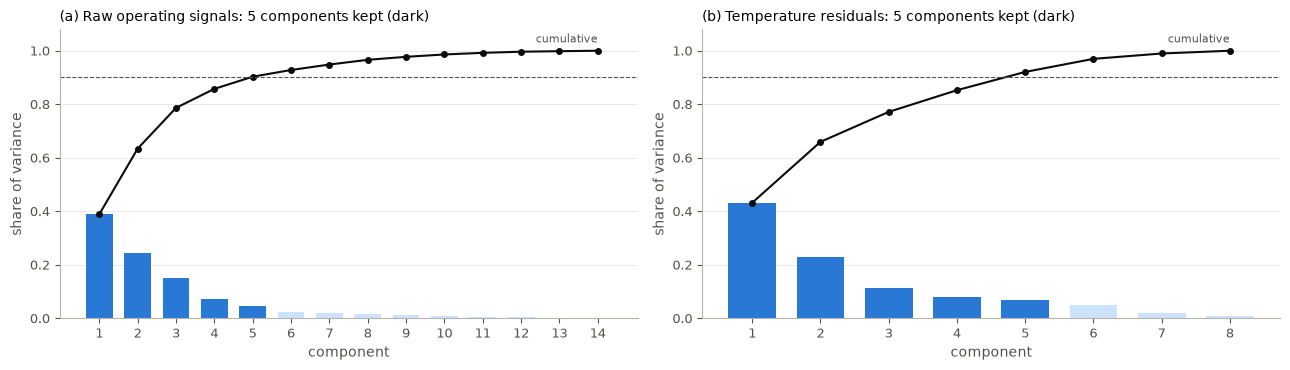

In [9]:
ref_h = healthy & (period == "reference")
raw_ok = scada[RAW_SIGNALS].notna().all(axis=1).to_numpy()
res_ok = resid.notna().all(axis=1).to_numpy()
pca_raw = PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(scada.loc[ref_h & raw_ok, RAW_SIGNALS])
pca_res = PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(resid[ref_h & res_ok])
print(f"(a) raw: {pca_raw.k_} components of {len(RAW_SIGNALS)}; (b) residuals: {pca_res.k_} of {len(TARGETS)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, mon, title in [(axes[0], pca_raw, "(a) Raw operating signals"), (axes[1], pca_res, "(b) Temperature residuals")]:
    evr = mon.full_pca_.explained_variance_ratio_
    x = np.arange(1, len(evr) + 1)
    ax.bar(x, evr, color=[PALETTE[0] if i < mon.k_ else "#cde2fb" for i in range(len(evr))], width=0.7)
    ax.plot(x, np.cumsum(evr), color=INK, lw=1.5, marker="o", ms=4)
    ax.axhline(VAR_EXPLAINED, color=MUTED, lw=0.8, ls="--")
    ax.annotate("cumulative", (x[-1], 1.0), xytext=(0, 6), textcoords="offset points", ha="right", fontsize=8, color=MUTED)
    ax.set_xticks(x)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("component", color=MUTED)
    ax.set_ylabel("share of variance", color=MUTED)
    ax.set_title(f"{title}: {mon.k_} components kept (dark)", loc="left", fontsize=10)
    style_ax(ax, grid_axis="y")
fig.tight_layout()
plt.show()

### Loadings

Loadings of the first components (diverging scale: purple positive, orange negative, white near zero). Below each map is an automatic plain-English summary from the largest loadings. The interpretation follows.

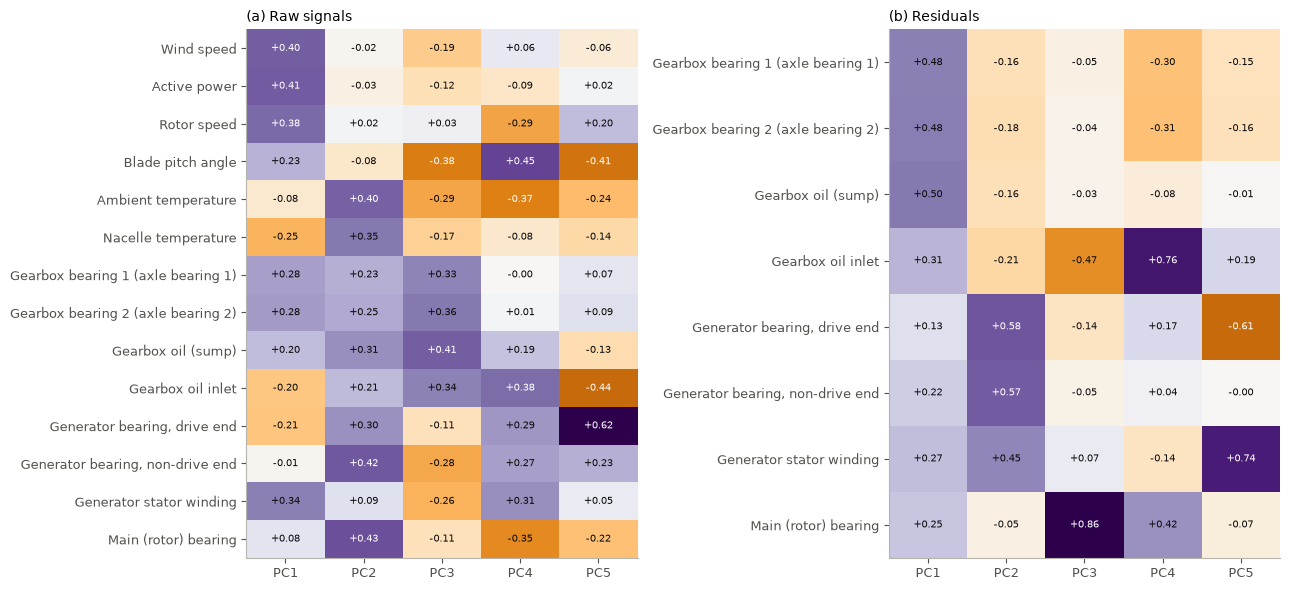

raw PC1 (39%): + Active power, + Wind speed, + Rotor speed
raw PC2 (25%): + Main (rotor) bearing, + Generator bearing, non-drive end, + Ambient temperature
raw PC3 (15%): + Gearbox oil (sump), − Blade pitch angle, + Gearbox bearing 2 (axle bearing 2)
raw PC4 (7%): + Blade pitch angle, + Gearbox oil inlet, − Ambient temperature
raw PC5 (5%): + Generator bearing, drive end, − Gearbox oil inlet, − Blade pitch angle
residual PC1 (43%): + Gearbox oil (sump), + Gearbox bearing 2 (axle bearing 2), + Gearbox bearing 1 (axle bearing 1)
residual PC2 (23%): + Generator bearing, drive end, + Generator bearing, non-drive end, + Generator stator winding
residual PC3 (11%): + Main (rotor) bearing, − Gearbox oil inlet, − Generator bearing, drive end
residual PC4 (8%): + Gearbox oil inlet, + Main (rotor) bearing, − Gearbox bearing 2 (axle bearing 2)
residual PC5 (7%): + Generator stator winding, − Generator bearing, drive end, + Gearbox oil inlet


In [10]:
def describe_pc(load, labels, n=3):
    order = np.argsort(-np.abs(load))[:n]
    return ", ".join(f"{'+' if load[i] > 0 else '−'} {labels[i]}" for i in order)

def loading_map(mon, names, n_show, title, ax):
    L = mon.full_pca_.components_[:n_show].T
    lim = np.abs(L).max()
    ax.imshow(L, cmap="PuOr", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(names)), [LBL[c] for c in names], fontsize=8.5)
    ax.set_xticks(range(n_show), [f"PC{i + 1}" for i in range(n_show)])
    for (i, j), v in np.ndenumerate(L):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7.5, color=INK if abs(v) < 0.6 * lim else "white")
    ax.set_title(title, loc="left", fontsize=10)
    style_ax(ax, grid_axis=None)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1]})
loading_map(pca_raw, RAW_SIGNALS, max(4, pca_raw.k_), "(a) Raw signals", axes[0])
loading_map(pca_res, TARGETS, max(4, pca_res.k_), "(b) Residuals", axes[1])
fig.tight_layout()
plt.show()

for name, mon, cols in [("raw", pca_raw, RAW_SIGNALS), ("residual", pca_res, TARGETS)]:
    for i in range(max(4, mon.k_)):
        print(f"{name} PC{i + 1} ({mon.full_pca_.explained_variance_ratio_[i]:.0%}): "
              f"{describe_pc(mon.full_pca_.components_[i], [LBL[c] for c in cols])}")

**Reading the components** (see the printed summaries above for exact loadings):

- **Raw PC1 (~40%) is operating level**: wind, power and rotor speed together with the load-driven temperatures (gearbox bearings, stator).
- **Raw PC2 (~25%) is ambient / season**: ambient and nacelle temperature with the slow-responding components (main bearing, generator non-drive-end bearing).
- **Raw PC3 (~15%) is gearbox heat vs pitch**: gearbox oil and bearings high while blade pitch is low, i.e. hard work below rated wind.
- **Raw PC4–5** pick out pitch activity above rated wind and the gear-oil-inlet / generator drive-end pair.
- **Residual PC1 (~43%) is gearbox thermal state**: both gearbox bearings and the gear oil run warmer or cooler than predicted *together*.
- **Residual PC2 (~23%) is generator thermal state**: both generator bearings and the stator winding together.
- **Residual PC3–5** are single components: main bearing (PC3), gear-oil inlet (PC4), generator drive-end bearing vs stator (PC5). Faults confined to one component should appear here, or in SPE.

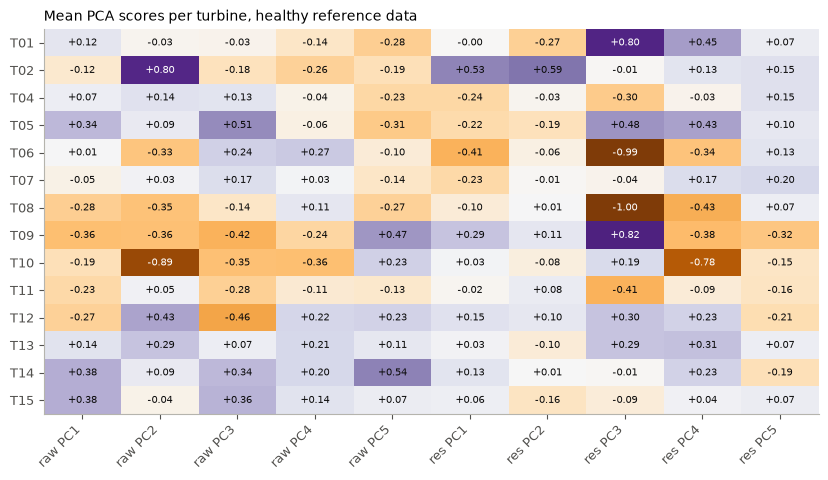

In [11]:
# Scores for every complete row (needed below); per-turbine mean scores on healthy reference data.
scores_raw = np.full((len(scada), pca_raw.k_), np.nan, dtype="float32")
scores_raw[raw_ok] = pca_raw.scores(scada.loc[raw_ok, RAW_SIGNALS])
scores_res = np.full((len(scada), pca_res.k_), np.nan, dtype="float32")
scores_res[res_ok] = pca_res.scores(resid[res_ok])

tid = scada["turbine_id"].to_numpy()
mean_raw = pd.DataFrame(scores_raw[ref_h]).groupby(tid[ref_h]).mean()
mean_res = pd.DataFrame(scores_res[ref_h]).groupby(tid[ref_h]).mean()
mean_raw.columns = [f"raw PC{i + 1}" for i in range(pca_raw.k_)]
mean_res.columns = [f"res PC{i + 1}" for i in range(pca_res.k_)]
mean_scores = pd.concat([mean_raw, mean_res], axis=1).rename(index=TL)

fig, ax = plt.subplots(figsize=(10, 5))
lim = np.abs(mean_scores.to_numpy()).max()
ax.imshow(mean_scores.to_numpy(), cmap="PuOr", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(mean_scores)), mean_scores.index)
ax.set_xticks(range(mean_scores.shape[1]), mean_scores.columns, rotation=45, ha="right")
for (i, j), v in np.ndenumerate(mean_scores.to_numpy()):
    ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7.5, color=INK if abs(v) < 0.6 * lim else "white")
ax.set_title("Mean PCA scores per turbine, healthy reference data", loc="left", fontsize=10)
style_ax(ax, grid_axis=None)
plt.show()

### SPE, T² and persistence

SPE and T² are computed for every row with complete data. The tables count healthy samples only. An **alarm** needs `N_CONSECUTIVE` exceedances in a row (6 = one hour). The count restarts at any gap in the healthy record, so a run can't bridge a stop. By construction about 1% of reference samples exceed each threshold. Higher rates in test mean the data has moved away from the reference structure; lower rates in training are because training residuals are in-sample (the models were fitted on them). Exceedances come in clusters, so even with 1-hour persistence the 99th-percentile thresholds give about one alarm per turbine-month. Step 6 calibrates thresholds to a lower false-alarm rate.

In [12]:
def contiguous_groups(times, turbine_ids):
    # Run id that changes at every turbine change or time gap > 10 min (rows must be sorted per turbine).
    t = times.to_numpy() if hasattr(times, "to_numpy") else times
    gap = np.r_[True, (np.diff(t) != np.timedelta64(10, "m")) | (turbine_ids[1:] != turbine_ids[:-1])]
    return np.cumsum(gap)

stats = {}
for name, mon, X, ok in [("raw", pca_raw, scada[RAW_SIGNALS], raw_ok), ("residual", pca_res, resid, res_ok)]:
    spe = np.full(len(scada), np.nan); t2 = np.full(len(scada), np.nan)
    spe[ok], t2[ok] = mon.statistics(X[ok])
    stats[name] = (spe, t2, mon.spe_limit_, mon.t2_limit_)

h_rows = np.flatnonzero(healthy)
grp = contiguous_groups(scada["time_stamp"].iloc[h_rows], tid[h_rows])
months_per = pd.Series(1, index=scada["time_stamp"].iloc[h_rows].dt.to_period("M")).groupby([tid[h_rows], period[h_rows]], observed=True).apply(lambda s: s.index.nunique())

rows = []
for name, (spe, t2, spe_lim, t2_lim) in stats.items():
    for stat, v, lim in [("SPE", spe, spe_lim), ("T2", t2, t2_lim)]:
        exceed = v[h_rows] > lim
        alarm = persistence(exceed, N_CONSECUTIVE, grp)
        onsets = alarm_onsets(alarm, grp)
        for p in SPLIT:
            m = (period[h_rows] == p)
            n_months = months_per.xs(p, level=1).sum()
            rows.append({"model": name, "stat": stat, "period": p, "exceed %": 100 * exceed[m].mean(),
                         "alarm %": 100 * alarm[m].mean(), "alarms / turbine-month": onsets[m].sum() / n_months})
alarm_table = pd.DataFrame(rows).pivot(index=["model", "stat"], columns="period").round(2)
alarm_table

exceed %                  alarm %                alarms / turbine-month               
period        reference  test training reference  test training              reference  test training
model    stat                                                                                        
raw      SPE        1.0  1.43     0.64      0.30  0.53     0.08                   0.91  1.01     0.32
         T2         1.0  0.94     0.74      0.15  0.12     0.09                   0.89  0.57     0.46
residual SPE        1.0  1.21     0.17      0.49  0.54     0.06                   1.38  1.29     0.26
         T2         1.0  1.20     0.12      0.43  0.67     0.02                   1.30  1.27     0.10

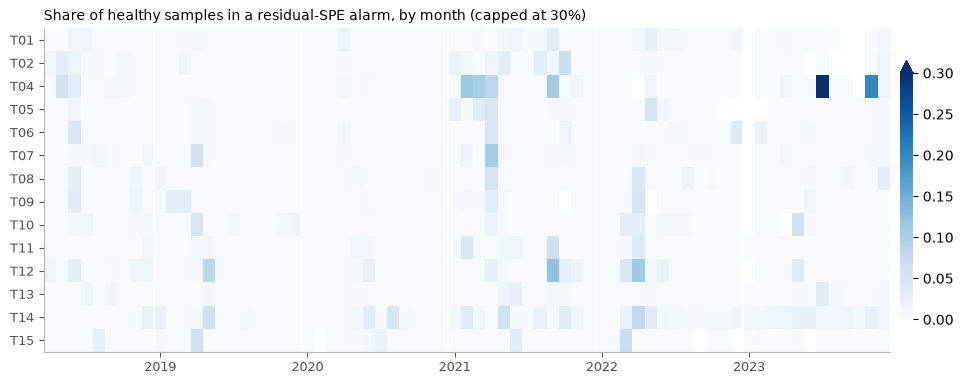

In [13]:
# Monthly alarm share (residual SPE, with persistence) per turbine: where the residual structure breaks down.
spe, _, lim, _ = stats["residual"]
alarm = persistence(spe[h_rows] > lim, N_CONSECUTIVE, grp)
am = pd.Series(alarm).groupby([tid[h_rows], scada["time_stamp"].iloc[h_rows].dt.to_period("M").to_numpy()]).mean().unstack()

fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(am.to_numpy(float), aspect="auto", cmap="Blues", vmin=0, vmax=0.3, interpolation="none")
ax.set_yticks(range(len(am)), [TL[t] for t in am.index])
mm = am.columns
ys = [i for i, m in enumerate(mm) if m.month == 1]
ax.set_xticks(ys, [mm[i].year for i in ys])
for i in ys:
    ax.axvline(i - 0.5, color="white", lw=1.5)
ax.set_title("Share of healthy samples in a residual-SPE alarm, by month (capped at 30%)", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, extend="max")
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

### Variant: PCA per wind-speed bin

The raw signals depend strongly on operating point, so a single PCA mixes regimes. Here a separate model (and threshold) is fitted for each wind-speed bin and compared with the global model, by SPE exceedance rate on healthy data. A per-bin model whose training and test rates stay closer to 1% is the better reference.

In [14]:
bins = pd.cut(scada["wind_speed"], WIND_BINS, right=False)
rows = []
for name, X, ok in [("raw", scada[RAW_SIGNALS], raw_ok), ("residual", resid, res_ok)]:
    spe_global = stats[name][0]
    lim_global = stats[name][2]
    for b in bins.cat.categories:
        in_bin = (bins == b).to_numpy() & ok
        mon_b = PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(X[in_bin & ref_h])
        spe_b, _ = mon_b.statistics(X[in_bin & healthy])
        p_b = period[in_bin & healthy]
        for p in SPLIT:
            rows.append({"model": name, "wind bin": str(b), "period": p, "components": mon_b.k_,
                         "global SPE exceed %": 100 * (spe_global[in_bin & healthy][p_b == p] > lim_global).mean(),
                         "per-bin SPE exceed %": 100 * (spe_b[p_b == p] > mon_b.spe_limit_).mean()})
bin_table = pd.DataFrame(rows)
bin_table.pivot(index=["model", "wind bin"], columns="period", values=["global SPE exceed %", "per-bin SPE exceed %"]).round(2)

global SPE exceed %                per-bin SPE exceed %               
period                      reference  test training            reference  test training
model    wind bin                                                                       
raw      [12, 40)                0.55  1.53     0.30                  1.0  2.91     0.85
         [3, 6)                  1.67  1.76     1.53                  1.0  0.92     0.46
         [6, 9)                  0.62  0.88     0.18                  1.0  1.88     0.49
         [9, 12)                 0.78  1.79     0.20                  1.0  2.07     0.31
residual [12, 40)                0.64  1.48     0.07                  1.0  5.24     0.17
         [3, 6)                  1.40  1.34     0.17                  1.0  0.81     0.29
         [6, 9)                  0.78  0.87     0.23                  1.0  5.08     0.21
         [9, 12)                 0.94  1.43     0.13                  1.0  5.53     0.17

## Step 4: Grouping turbines

Each turbine is described by one feature vector from healthy reference data:

- mean raw-PCA scores and mean residual-PCA scores (Step 3)
- residual mean and SD for each temperature (Step 2)
- slope of each raw-PCA score against wind speed (how the turbine's operating structure changes with wind)

Features are z-scored across turbines. Each block is then scaled by 1/√(block size), so no block dominates because it has more columns. Four methods are compared.

In [15]:
w = scada["wind_speed"].to_numpy()
blocks = {
    "mean scores": mean_scores.set_axis(TURBINES),
    "residual stats": pd.concat([resid[ref_h].groupby(tid[ref_h]).mean().add_suffix(" mean"),
                                 resid[ref_h].groupby(tid[ref_h]).std().add_suffix(" sd")], axis=1),
    "score-wind slopes": pd.DataFrame({
        f"raw PC{j + 1} slope": [np.polyfit(w[ref_h & (tid == t) & raw_ok], scores_raw[ref_h & (tid == t) & raw_ok, j], 1)[0]
                                 for t in TURBINES] for j in range(pca_raw.k_)}, index=TURBINES),
}
parts = []
for name, b in blocks.items():
    z = (b - b.mean()) / b.std(ddof=0).replace(0, 1)
    parts.append(z / np.sqrt(b.shape[1]))
F = pd.concat(parts, axis=1)
F.index.name = "turbine_id"
Fx = F.to_numpy()
D = np.sqrt(((Fx[:, None] - Fx[None]) ** 2).sum(-1))
print(f"Feature matrix: {F.shape[0]} turbines x {F.shape[1]} features")

Feature matrix: 14 turbines x 31 features


### k-means (silhouette) and hierarchical clustering (dendrogram)

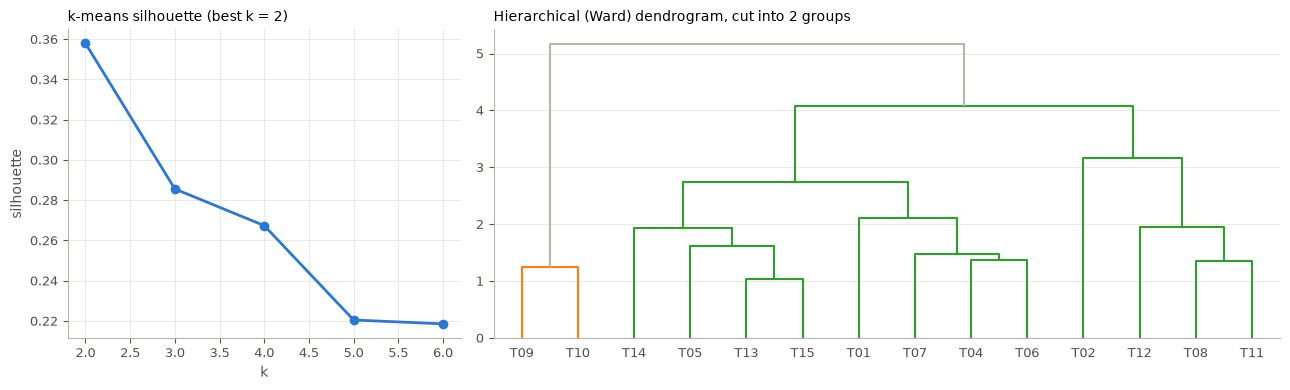

In [16]:
ks = range(2, 7)
sil = {k: silhouette_score(Fx, KMeans(k, n_init=50, random_state=0).fit_predict(Fx)) for k in ks}
best_k = max(sil, key=sil.get)
labels = {"k-means": KMeans(best_k, n_init=50, random_state=0).fit_predict(Fx)}
Z = linkage(Fx, method="ward")
labels["hierarchical"] = fcluster(Z, best_k, criterion="maxclust") - 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].plot(list(sil), list(sil.values()), color=PALETTE[0], marker="o", lw=2)
axes[0].set_xlabel("k", color=MUTED)
axes[0].set_ylabel("silhouette", color=MUTED)
axes[0].set_title(f"k-means silhouette (best k = {best_k})", loc="left", fontsize=10)
style_ax(axes[0])
dendrogram(Z, labels=[TL[t] for t in TURBINES], ax=axes[1], color_threshold=Z[-(best_k - 1), 2],
           above_threshold_color=AXIS)
axes[1].set_title(f"Hierarchical (Ward) dendrogram, cut into {best_k} groups", loc="left", fontsize=10)
style_ax(axes[1], grid_axis="y")
fig.tight_layout()
plt.show()

### kNN graph communities and spectral clustering (eigengap)

The **kNN graph** links each turbine to its `K_GRAPH` nearest neighbours in feature space (symmetrised), with Gaussian edge weights. Communities come from Leiden and Louvain. **Spectral clustering** uses a fully connected Gaussian affinity, and *k* is chosen at the largest gap in the normalised-Laplacian eigenvalues.

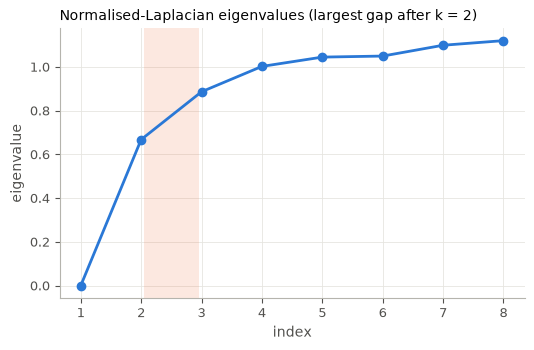

Agreement between methods (adjusted Rand index, 1 = identical):


,k-means,hierarchical,Leiden,Louvain,spectral
k-means,1.00,1.00,0.03,0.03,1.00
hierarchical,1.00,1.00,0.03,0.03,1.00
Leiden,0.03,0.03,1.00,1.00,0.03
Louvain,0.03,0.03,1.00,1.00,0.03
spectral,1.00,1.00,0.03,0.03,1.00


In [17]:
sigma = np.median(np.sort(D, 1)[:, 1:K_GRAPH + 1])
W_full = np.exp(-D ** 2 / (2 * sigma ** 2))
np.fill_diagonal(W_full, 0)
nn = np.argsort(D, 1)[:, 1:K_GRAPH + 1]
A = np.zeros_like(D, dtype=bool)
for i, row in enumerate(nn):
    A[i, row] = True
A = A | A.T
edges = [(i, j, W_full[i, j]) for i in range(len(TURBINES)) for j in range(i + 1, len(TURBINES)) if A[i, j]]

g = ig.Graph(n=len(TURBINES), edges=[(i, j) for i, j, _ in edges])
g.es["weight"] = [wt for *_, wt in edges]
labels["Leiden"] = np.array(leidenalg.find_partition(g, leidenalg.ModularityVertexPartition, weights="weight",
                                                     seed=0).membership)
G = nx.Graph()
G.add_nodes_from(range(len(TURBINES)))
G.add_weighted_edges_from(edges)
lou = nx.community.louvain_communities(G, weight="weight", seed=0)
labels["Louvain"] = np.array([next(c for c, comm in enumerate(lou) if i in comm) for i in range(len(TURBINES))])

deg = W_full.sum(1)
L_sym = np.eye(len(D)) - W_full / np.sqrt(np.outer(deg, deg))
eig = np.sort(np.linalg.eigvalsh(L_sym))
gaps = np.diff(eig[:8])
k_spec = int(np.argmax(gaps[1:]) + 2)   # ignore the gap after the first eigenvalue (k=1)
labels["spectral"] = SpectralClustering(k_spec, affinity="precomputed", random_state=0).fit_predict(W_full)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, 9), eig[:8], color=PALETTE[0], marker="o", lw=2)
ax.axvspan(k_spec + 0.05, k_spec + 0.95, color=PALETTE[1], alpha=0.15, lw=0)
ax.set_xlabel("index", color=MUTED)
ax.set_ylabel("eigenvalue", color=MUTED)
ax.set_title(f"Normalised-Laplacian eigenvalues (largest gap after k = {k_spec})", loc="left", fontsize=10)
style_ax(ax)
plt.show()

ari = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in labels] for a in labels],
                   index=list(labels), columns=list(labels))
print("Agreement between methods (adjusted Rand index, 1 = identical):")
ari.round(2)

### Groups on the farm layout

Each panel colours the turbines by one method's groups, with the kNN-graph edges drawn as lines (thicker = more similar). To check whether groups track position or wake exposure, each turbine's **wake exposure** is the share of reference time when another turbine within 10 rotor diameters sits upwind of it, within ±15° of the farm-mean wind direction.

Prevailing direction (circular mean): 218°


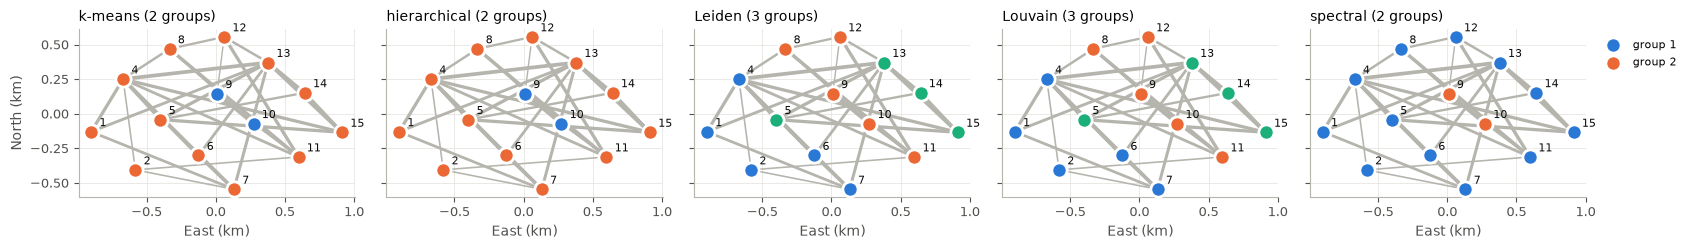

In [18]:
lat0 = np.deg2rad(turbines["latitude"].mean())
xy = np.c_[(turbines["longitude"] - turbines["longitude"].mean()) * 111.32 * np.cos(lat0),
           (turbines["latitude"] - turbines["latitude"].mean()) * 110.57]
rotor_km = turbines["rotor_diameter_m"].iloc[0] / 1000

# Farm-mean wind direction per reference timestamp (circular mean over turbines).
wd = scada.loc[ref_h, ["time_stamp", "wind_direction"]]
rad = np.deg2rad(wd["wind_direction"].to_numpy())
farm_dir = (np.rad2deg(np.arctan2(pd.Series(np.sin(rad)).groupby(wd["time_stamp"].to_numpy()).mean(),
                                  pd.Series(np.cos(rad)).groupby(wd["time_stamp"].to_numpy()).mean())) % 360).to_numpy()

def wake_exposure(i, half_angle=15, max_dist_d=10):
    waked = np.zeros(len(farm_dir), dtype=bool)
    for j in range(len(xy)):
        if j == i:
            continue
        dx, dy = xy[j] - xy[i]
        dist = np.hypot(dx, dy) / rotor_km
        if dist > max_dist_d:
            continue
        bearing = np.rad2deg(np.arctan2(dx, dy)) % 360   # direction from i towards j (compass)
        diff = np.abs((farm_dir - bearing + 180) % 360 - 180)
        waked |= diff < half_angle                       # wind coming from j's direction
    return waked.mean()

layout = pd.DataFrame({"x_km": xy[:, 0], "y_km": xy[:, 1], "elevation_m": turbines["elevation_m"].to_numpy(),
                       "wake_exposure": [wake_exposure(i) for i in range(len(xy))]}, index=TURBINES)
print(f"Prevailing direction (circular mean): {np.rad2deg(np.arctan2(np.sin(np.deg2rad(farm_dir)).mean(), np.cos(np.deg2rad(farm_dir)).mean())) % 360:.0f}°")

fig, axes = plt.subplots(1, len(labels), figsize=(17, 4), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes, labels.items()):
    for i, j, wt in edges:
        ax.plot(*xy[[i, j]].T, color=AXIS, lw=0.5 + 3 * wt, zorder=1)
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(*xy[m].T, s=120, color=PALETTE[c % len(PALETTE)], edgecolor="white", lw=2, zorder=3,
                   label=f"group {c + 1}")
    for i, t in enumerate(TURBINES):
        ax.annotate(str(t), xy[i], xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK)
    ax.set_aspect("equal")
    ax.set_title(f"{name} ({len(np.unique(lab))} groups)", loc="left", fontsize=10)
    style_ax(ax)
axes[0].set_ylabel("North (km)", color=MUTED)
for ax in axes:
    ax.set_xlabel("East (km)", color=MUTED)
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

In [19]:
def eta_squared(values, lab):
    # Share of a variable's variance explained by group membership (0 = unrelated, 1 = fully).
    v = np.asarray(values, float)
    groups = [v[lab == c] for c in np.unique(lab)]
    between = sum(len(gv) * (gv.mean() - v.mean()) ** 2 for gv in groups)
    return between / ((v - v.mean()) ** 2).sum()

pos_k = {name: KMeans(len(np.unique(lab)), n_init=50, random_state=0).fit_predict(xy) for name, lab in labels.items()}
track = pd.DataFrame({name: {
    "groups": len(np.unique(lab)),
    "ARI vs position clusters": adjusted_rand_score(lab, pos_k[name]),
    "η² east": eta_squared(layout["x_km"], lab), "η² north": eta_squared(layout["y_km"], lab),
    "η² elevation": eta_squared(layout["elevation_m"], lab),
    "η² wake exposure": eta_squared(layout["wake_exposure"], lab)} for name, lab in labels.items()}).T
display(layout.assign(turbine=[TL[t] for t in TURBINES]).set_index("turbine").round(3).T)
track.round(2)

turbine,T01,T02,T04,T05,T06,T07,T08,T09,T10,T11,T12,T13,T14,T15
x_km,-0.900,-0.581,-0.669,-0.400,-0.125,0.131,-0.334,0.010,0.273,0.599,0.061,0.379,0.644,0.913
y_km,-0.130,-0.406,0.251,-0.042,-0.301,-0.546,0.469,0.145,-0.071,-0.312,0.556,0.370,0.152,-0.134
elevation_m,212.260,200.460,208.910,201.380,199.030,180.240,200.130,187.040,186.880,204.840,219.310,220.000,219.460,228.150
wake_exposure,0.176,0.192,0.467,0.595,0.518,0.267,0.514,0.856,0.723,0.412,0.678,0.691,0.602,0.322


,groups,ARI vs position clusters,η² east,η² north,η² elevation,η² wake exposure
k-means,2.0,-0.03,0.01,0.00,0.29,0.35
hierarchical,2.0,-0.03,0.01,0.00,0.29,0.35
Leiden,3.0,0.19,0.42,0.28,0.33,0.46
Louvain,3.0,0.19,0.42,0.28,0.33,0.46
spectral,2.0,-0.03,0.01,0.00,0.29,0.35


**Do the groups track layout?** η² close to 1 means a layout variable is almost fully explained by group membership; ARI against position-based clusters near 1 means the groups are essentially spatial. With 14 turbines, η² below about 0.3 is within what random groupings produce.

- **k-means, hierarchical and spectral agree exactly**: T09 and T10 form their own group. They sit in the middle of the farm and are the **most waked** turbines (exposure 0.86 and 0.72 against a farm median of about 0.5), and their gear-oil-inlet residuals run about 3 °C below the others (Step 2 boxplots). The grouping tracks wake exposure partly (η² ≈ 0.35) but not position (ARI ≈ 0).
- **Leiden and Louvain agree with each other** (3 groups) but not with the others. Their groups line up a little more with east–west position and wake exposure, but are less clearly separated in feature space.

So the strongest structure is "two heavily waked central turbines vs the rest", not a spatial split. The hierarchical result is frozen (three methods agree and it has the best silhouette). Peers are taken from nearest neighbours in feature space, so they don't depend on this choice.

### Freeze the groups

The groups from `GROUP_METHOD` are frozen, along with each turbine's `K_PEERS` nearest peers in the reference feature space. Both are saved to `data/Penmanshiel/analysis/groups.parquet` and used unchanged in Steps 5–6.

In [20]:
group_of = dict(zip(TURBINES, labels[GROUP_METHOD]))
peer_idx = np.argsort(D, 1)[:, 1:K_PEERS + 1]
peers = {t: [TURBINES[j] for j in peer_idx[i]] for i, t in enumerate(TURBINES)}
frozen = pd.DataFrame({"turbine_id": TURBINES, "group": [group_of[t] for t in TURBINES],
                       "peers": [peers[t] for t in TURBINES], **{f"group_{m}": labels[m] for m in labels}})
frozen.to_parquet(OUT / "groups.parquet", index=False)
frozen.assign(turbine=frozen["turbine_id"].map(TL), peers=frozen["peers"].map(lambda p: ", ".join(TL[x] for x in p)))[
    ["turbine", "group", "peers"]].set_index("turbine").T

turbine,T01,T02,T04,T05,T06,T07,T08,T09,T10,T11,T12,T13,T14,T15
group,1,1,1,1,1,1,1,0,0,1,1,1,1,1
peers,"T04, T13, T07, T11","T07, T11, T04, T12","T13, T06, T07, T15","T13, T15, T04, T07","T04, T07, T13, T15","T04, T06, T13, T05","T11, T04, T12, T06","T10, T11, T12, T08","T09, T11, T08, T07","T08, T12, T04, T01","T11, T13, T08, T01","T15, T04, T05, T14","T13, T15, T05, T06","T13, T05, T04, T14"


## Step 5: Fleet-relative drift

**Peer residual** = a turbine's residual minus the median residual of its frozen peers at the same timestamp (healthy samples, at least 2 peers present). A shift that hits the whole farm (weather the model misses, a firmware change) cancels out; a shift in one turbine does not.

Both own and peer residuals are aggregated **daily within wind-speed bins**: a bin's daily mean needs at least `MIN_BIN_COUNT` samples, and the daily value is the mean over bins. This stops a windy day from looking different from a calm one just because of its mix of operating points. Each daily series is standardised with its reference-period mean and SD before the sequential tests.

In [21]:
day = scada["time_stamp"].dt.floor("D").to_numpy()
wbin = np.digitize(scada["wind_speed"].to_numpy(), WIND_BINS[1:-1])   # 0..len(bins)-2

# Wide (time x turbine) healthy residual per target -> peer median -> peer residual (back in long form).
long_h = scada.loc[healthy, ["turbine_id", "time_stamp"]].reset_index()
peer_res = pd.DataFrame(np.nan, index=scada.index, columns=TARGETS, dtype="float32")
for y in TARGETS:
    wide = pd.Series(resid.loc[healthy, y].to_numpy(), index=pd.MultiIndex.from_frame(long_h[["time_stamp", "turbine_id"]])).unstack()
    wide = wide.reindex(columns=TURBINES)
    vals = wide.to_numpy()
    out = np.full_like(vals, np.nan)
    for i, t in enumerate(TURBINES):
        pv = vals[:, [TURBINES.index(p) for p in peers[t]]]
        enough = (~np.isnan(pv)).sum(1) >= 2
        med = np.full(len(vals), np.nan)
        med[enough] = np.nanmedian(pv[enough], axis=1)
        out[:, i] = vals[:, i] - med
    pr = pd.DataFrame(out, index=wide.index, columns=TURBINES).stack().rename("v")
    idx = pd.MultiIndex.from_frame(long_h[["time_stamp", "turbine_id"]])
    peer_res.loc[long_h["index"].to_numpy(), y] = pr.reindex(idx).to_numpy()

def daily_binned(values: pd.DataFrame, mask):
    # Daily value per (turbine, day): mean over wind bins of the bin's daily mean (bins with enough samples).
    keys = pd.DataFrame({"turbine_id": tid[mask], "day": day[mask], "bin": wbin[mask]})
    v = values[mask].reset_index(drop=True)
    g = pd.concat([keys, v], axis=1).groupby(["turbine_id", "day", "bin"])
    means, counts = g.mean(), g.size()
    means[counts < MIN_BIN_COUNT] = np.nan
    return means.groupby(level=["turbine_id", "day"]).mean()

own_daily = daily_binned(resid, healthy)
peer_daily = daily_binned(peer_res, healthy & peer_res.notna().any(axis=1).to_numpy())
# Complete daily calendar per turbine, so the sequential tests see gaps as NaN.
all_days = pd.date_range(scada["time_stamp"].min().floor("D"), scada["time_stamp"].max().floor("D"), freq="D")
full_idx = pd.MultiIndex.from_product([TURBINES, all_days], names=["turbine_id", "day"])
own_daily, peer_daily = own_daily.reindex(full_idx), peer_daily.reindex(full_idx)
day_period = pd.Series(pm.period_of(pd.Series(all_days), SPLIT), index=all_days)

def standardise(daily):
    ref = daily[day_period.reindex(daily.index.get_level_values("day")).to_numpy() == "reference"]
    mu, sd = ref.groupby(level="turbine_id").mean(), ref.groupby(level="turbine_id").std()
    return (daily - mu.reindex(daily.index.get_level_values(0)).to_numpy()) / sd.reindex(daily.index.get_level_values(0)).to_numpy()

own_z, peer_z = standardise(own_daily), standardise(peer_daily)
print(f"Daily series: {len(TURBINES)} turbines x {len(all_days)} days x {len(TARGETS)} targets")
print("Share of days with a value (from the reference start):",
      own_daily.loc[(slice(None), slice(SPLIT['reference'][0], None)), :].notna().mean().round(2).to_dict())

Daily series: 14 turbines x 2769 days x 8 targets
Share of days with a value (from the reference start): {'front_bearing_temperature': 0.9, 'rear_bearing_temperature': 0.9, 'gear_oil_temperature': 0.9, 'gear_oil_inlet_temperature': 0.9, 'generator_bearing_front_temperature': 0.9, 'generator_bearing_rear_temperature': 0.9, 'stator_temperature_1': 0.9, 'rotor_bearing_temp': 0.9}


### CUSUM and Page-Hinkley

Both run on each turbine's daily standardised series from the start of the reference period, separately on own and peer residuals, and reset after each alarm. Daily residuals are strongly autocorrelated (weather lasts for days), so textbook thresholds (h = 5) would alarm several times a month. Instead, **h (CUSUM, k = 0.5) and λ (Page-Hinkley, δ = 0.5) are calibrated on the reference period** to `SERIES_FA_TARGET` false alarms per turbine-target-month (about one per series per year). Interpretation:

| own fires | peer fires | reading |
|---|---|---|
| yes | no | farm-wide (common-mode) shift: the turbine moved, but so did its peers |
| yes | yes | turbine-specific change |
| no | yes | turbine-specific change hidden in the own residual by an opposite farm-wide shift |

In [22]:
start = pd.Timestamp(SPLIT["reference"][0])
ref_last = pd.Timestamp(SPLIT["reference"][1]) - pd.Timedelta(days=1)
ref_months = ((ref_last - start).days + 1) / 30.44
RUN = {"CUSUM": lambda x, v: cusum(x, CUSUM_K, v)[0], "Page-Hinkley": lambda x, v: page_hinkley(x, PH_DELTA, v)}

def calibrate(series_list, run, target, months):
    # Smallest threshold whose total alarm count over `series_list` is at most target * months * len(series_list).
    for v in CAL_GRID:
        if sum(run(x, v).sum() for x in series_list) <= target * months * len(series_list):
            return v
    return CAL_GRID[-1]

THRESH = {}
for series_name, zdf in [("own", own_z), ("peer", peer_z)]:
    ref_series = [zdf.loc[t].loc[start:ref_last, y].to_numpy() for t in TURBINES for y in TARGETS]
    for det, run in RUN.items():
        THRESH[(det, series_name)] = calibrate(ref_series, run, SERIES_FA_TARGET, ref_months)
print("Calibrated thresholds:", {f"{d} {s}": v for (d, s), v in THRESH.items()})

alarm_rows = []
for series_name, zdf in [("own", own_z), ("peer", peer_z)]:
    for t in TURBINES:
        zt = zdf.loc[t].loc[start:]
        for y in TARGETS:
            x = zt[y].to_numpy()
            for det, run in RUN.items():
                for d in zt.index[run(x, THRESH[(det, series_name)])]:
                    alarm_rows.append((series_name, det, t, y, d))
alarms = pd.DataFrame(alarm_rows, columns=["series", "detector", "turbine_id", "target", "day"])
alarms["period"] = day_period.reindex(alarms["day"]).to_numpy()

n_days = {p: ((day_period == p) & (day_period.index >= start)).sum() for p in SPLIT}
rate = (alarms.groupby(["detector", "series", "period"], observed=True).size()
        .unstack("period").reindex(columns=list(SPLIT)))
rate = rate / pd.Series({p: n_days[p] / 30.44 * len(TURBINES) * len(TARGETS) for p in SPLIT})
print("Alarms per turbine-target-month:")
rate.round(3)

Calibrated thresholds: {'CUSUM own': np.float64(17.0), 'Page-Hinkley own': np.float64(14.5), 'CUSUM peer': np.float64(17.5), 'Page-Hinkley peer': np.float64(13.5)}


Alarms per turbine-target-month:


period               reference  training   test
detector     series                            
CUSUM        own         0.080     0.119  0.386
             peer        0.078     0.166  0.564
Page-Hinkley own         0.078     0.020  0.075
             peer        0.082     0.035  0.122

In [23]:
def classify_alarms(det):
    a = alarms[alarms["detector"] == det]
    out = []
    for (t, y), g in a.groupby(["turbine_id", "target"]):
        own_days, peer_days = g.loc[g["series"] == "own", "day"], g.loc[g["series"] == "peer", "day"]
        near = lambda d, other: (np.abs((other - d).dt.days) <= ALIGN_DAYS).any() if len(other) else False
        for d in own_days:
            out.append((t, y, d, "turbine-specific (both)" if near(d, peer_days) else "farm-wide (own only)"))
        for d in peer_days:
            if not near(d, own_days):
                out.append((t, y, d, "turbine-specific (peer only)"))
    return pd.DataFrame(out, columns=["turbine_id", "target", "day", "class"])

cls = classify_alarms("CUSUM")
cls["period"] = day_period.reindex(cls["day"]).to_numpy()
print("CUSUM alarm classes, by period:")
display(pd.crosstab(cls["class"], cls["period"]))
pd.crosstab(cls["turbine_id"].map(TL), cls["class"])

CUSUM alarm classes, by period:


period,reference,test,training
class,,,
farm-wide (own only),45,511,40
turbine-specific (both),62,1349,120
turbine-specific (peer only),41,1000,76


class,farm-wide (own only),turbine-specific (both),turbine-specific (peer only)
turbine_id,,,
T01,29,106,83
T02,69,42,55
T04,56,82,40
T05,46,78,33
T06,92,64,37
T07,46,77,135
T08,19,75,57
T09,10,160,115
T10,15,240,88


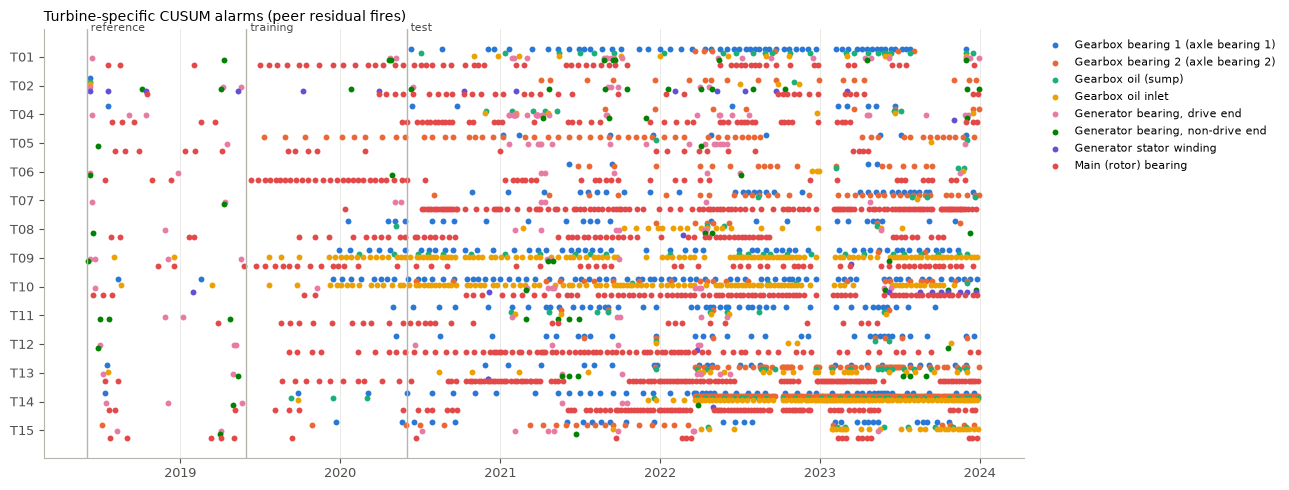

In [24]:
# Timeline of turbine-specific CUSUM alarms (both / peer only), coloured by target.
ts = cls[cls["class"] != "farm-wide (own only)"]
fig, ax = plt.subplots(figsize=(13, 5))
for k, y in enumerate(TARGETS):
    s = ts[ts["target"] == y]
    ax.scatter(s["day"], [TURBINES.index(t) + (k - 3.5) * 0.08 for t in s["turbine_id"]], s=18,
               color=PALETTE[k], label=LBL[y], lw=0)
for name, (s0, e0) in SPLIT.items():
    ax.axvline(pd.Timestamp(s0), color=AXIS, lw=1)
    ax.annotate(name, (pd.Timestamp(s0), -0.9), xytext=(3, 0), textcoords="offset points", fontsize=8, color=MUTED)
ax.set_yticks(range(len(TURBINES)), [TL[t] for t in TURBINES])
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)
ax.set_title("Turbine-specific CUSUM alarms (peer residual fires)", loc="left", fontsize=10)
style_ax(ax, grid_axis="x")
fig.tight_layout()
plt.show()

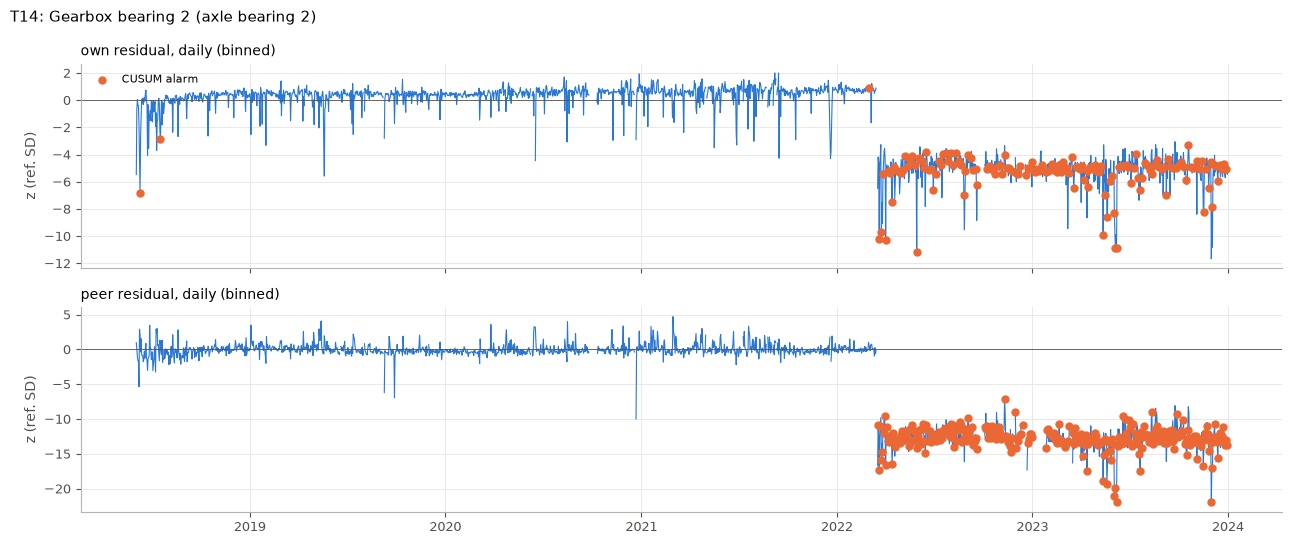

In [25]:
# Example: the turbine/target with the most turbine-specific alarms in the test period.
pool = ts[ts["period"] == "test"] if (ts["period"] == "test").any() else ts
ex = pool.groupby(["turbine_id", "target"]).size().idxmax()
t_ex, y_ex = ex
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, (name, zdf) in zip(axes, [("own", own_z), ("peer", peer_z)]):
    z = zdf.loc[t_ex, y_ex].loc[start:]
    ax.plot(z.index, z.to_numpy(), color=PALETTE[0], lw=0.8)
    a = alarms[(alarms["series"] == name) & (alarms["detector"] == "CUSUM") & (alarms["turbine_id"] == t_ex) & (alarms["target"] == y_ex)]
    ax.scatter(a["day"], z.reindex(a["day"]).to_numpy(), color=PALETTE[1], s=25, zorder=3, label="CUSUM alarm")
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_ylabel("z (ref. SD)", color=MUTED)
    ax.set_title(f"{name} residual, daily (binned)", loc="left", fontsize=10)
    style_ax(ax)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle(f"{TL[t_ex]}: {LBL[y_ex]}", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Example: T14, gearbox bearing 2.** The level drops by about 5 reference SDs in the own residual and about 13 SDs relative to peers in mid-March 2022, and stays there. The status log has a 3-day manual stop from 2022-03-15 to 03-18 with the operator comment **"HS Bearing Replacement"** (high-speed gearbox bearing). The weekly mean bearing temperature fell from about 62 °C to about 53 °C, so this is a real component change. CUSUM keeps re-alarming afterwards because the turbine never returns to its old baseline. In operation, a confirmed change like this would trigger re-fitting the turbine's model (re-baselining) rather than repeated alarms. The largest change point in the PELT table below is this event.

### Offline change points (PELT) on peer residuals

`ruptures` penalised change-point search with an L2 cost (PELT; run through `KernelCPD(kernel="linear")`, the C implementation of the same cost; minimum segment 14 days, penalty `PELT_PENALTY`) on each daily standardised peer-residual series, with gaps dropped. Each change point is classified as a **step** (different constant level either side) or a **ramp** (level then linear trend) on a ±30-day window. The size is in reference SDs.

In [26]:
cp_rows = []
for t in TURBINES:
    for y in TARGETS:
        s = peer_z.loc[t, y].loc[start:].dropna()
        if len(s) < 60:
            continue
        # KernelCPD with a linear kernel is the same L2 cost and penalised (PELT) search as rpt.Pelt(model="l2"),
        # implemented in C: identical breakpoints, ~1000x faster on 2000-day series.
        bkps = [int(b) for b in rpt.KernelCPD(kernel="linear", min_size=14).fit(s.to_numpy()[:, None]).predict(pen=PELT_PENALTY)[:-1]]
        for b in bkps:
            kind, size = classify_change(s.to_numpy(), b, 30)
            cp_rows.append((t, y, s.index[b], kind, size))
cps = pd.DataFrame(cp_rows, columns=["turbine_id", "target", "day", "kind", "size_sd"])
cps["period"] = day_period.reindex(cps["day"]).to_numpy()
print(f"{len(cps)} change points")
display(pd.crosstab(cps["kind"], cps["period"]))
cps.assign(turbine=cps["turbine_id"].map(TL), target=cps["target"].map(LBL)).sort_values(
    "size_sd", key=np.abs, ascending=False).head(15)[["turbine", "target", "day", "kind", "size_sd"]].round({"size_sd": 2})

708 change points


period,reference,test,training
kind,,,
ramp,9,48,5
step,105,487,54


,turbine,target,day,kind,size_sd
603,T14,Gearbox bearing 2 (axle bearing 2),2022-03-18,step,-12.93
616,T14,Gearbox oil inlet,2022-03-13,ramp,-9.52
657,T14,Main (rotor) bearing,2022-12-14,ramp,-8.05
133,T04,"Generator bearing, drive end",2022-03-21,ramp,6.56
617,T14,Gearbox oil inlet,2022-03-29,step,-5.98
539,T13,Gearbox bearing 2 (axle bearing 2),2023-05-20,step,5.39
658,T14,Main (rotor) bearing,2023-01-29,step,-5.33
536,T13,Gearbox bearing 2 (axle bearing 2),2023-02-01,step,-5.11
628,T14,Gearbox oil inlet,2023-11-08,ramp,-4.95
130,T04,"Generator bearing, drive end",2021-04-09,step,-4.84


### Do change points line up with stops and service?

Events are Stop events in the turbine-fault classes, plus maintenance and service stops, lasting at least 1 hour (from the status log, as in the EDA). A change point **matches** if such an event on the same turbine starts within ±`ALIGN_DAYS` days. The chance baseline circularly shifts each turbine's event times by a random offset (`N_SHUFFLE` times). This keeps how events cluster in time but breaks any link to the change points.

993 events; change points matching an event within ±14 d: 62.1% (chance 52.7%, 95% range 47.6%–57.8%); p = 0.002


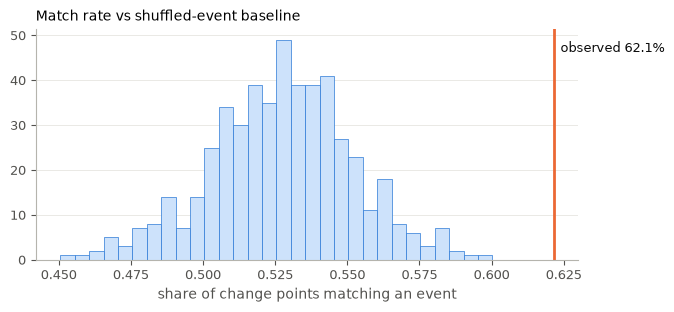

In [27]:
FAULT_CATS = ["Generator and Converter errors (20)", "Pitch errors (18)", "Mechanical error (23)", "Electrical error (24)",
              "Sensor error (21)", "Temperature error (22)", "Controller error of the WP3100 (16)", "Repeated error  (25)",
              "Safety chain (13)", "Safety stop of WEC (15)", "Emergency stop switch (Converter) (12)",
              "Emergency stop switch (Nacelle) (11)", "WEC Shutdown (1)", "Overspeed (14)", "Manual stop (service)  (9)"]
ev = status[(status["status"] == "Stop") & status["service_contract_category"].isin(FAULT_CATS)
            & (status["duration"] >= pd.Timedelta("1h"))]
ev = ev[ev["timestamp_start"] >= start]
ev_days = {t: ev.loc[ev["turbine_id"] == t, "timestamp_start"].dt.floor("D").to_numpy() for t in TURBINES}
span0, span1 = start.to_datetime64(), all_days[-1].to_datetime64()
span = (span1 - span0).astype("timedelta64[D]").astype(int)

def match_rate(ev_by_turbine):
    hits = 0
    for t, g in cps.groupby("turbine_id"):
        e = ev_by_turbine[t]
        if len(e) == 0:
            continue
        diff = np.abs((g["day"].to_numpy()[:, None] - e[None, :]).astype("timedelta64[D]").astype(int))
        hits += (diff.min(1) <= ALIGN_DAYS).sum()
    return hits / len(cps)

observed = match_rate(ev_days)
rng = np.random.default_rng(0)
null = []
for _ in range(N_SHUFFLE):
    shifted = {}
    for t, e in ev_days.items():
        off = (e - span0).astype("timedelta64[D]").astype(int)
        shifted[t] = span0 + ((off + rng.integers(span)) % span).astype("timedelta64[D]")
    null.append(match_rate(shifted))
null = np.array(null)
p_value = (1 + (null >= observed).sum()) / (1 + N_SHUFFLE)
print(f"{len(ev)} events; change points matching an event within ±{ALIGN_DAYS} d: {observed:.1%} "
      f"(chance {null.mean():.1%}, 95% range {np.percentile(null, 2.5):.1%}–{np.percentile(null, 97.5):.1%}); p = {p_value:.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(null, bins=30, color="#cde2fb", edgecolor=PALETTE[0], lw=0.5)
ax.axvline(observed, color=PALETTE[1], lw=2)
ax.annotate(f"observed {observed:.1%}", (observed, ax.get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points",
            fontsize=9, color=INK)
ax.set_xlabel("share of change points matching an event", color=MUTED)
ax.set_title("Match rate vs shuffled-event baseline", loc="left", fontsize=10)
style_ax(ax, grid_axis="y")
plt.show()

### Peer links over time

For rolling 60-day windows (14-day step), each turbine is summarised by its mean daily residual for each temperature. Edge weights between turbines use the same Gaussian kernel as Step 4, with the width set from the reference windows. A turbine's **peer-link strength** is its mean edge weight to its frozen peers. A turbine is flagged when the strength drops more than 3 SD below its own reference-period mean. Windows inside the training period are greyed out: residuals there are in-sample (close to zero for every turbine), which makes all turbines look alike.

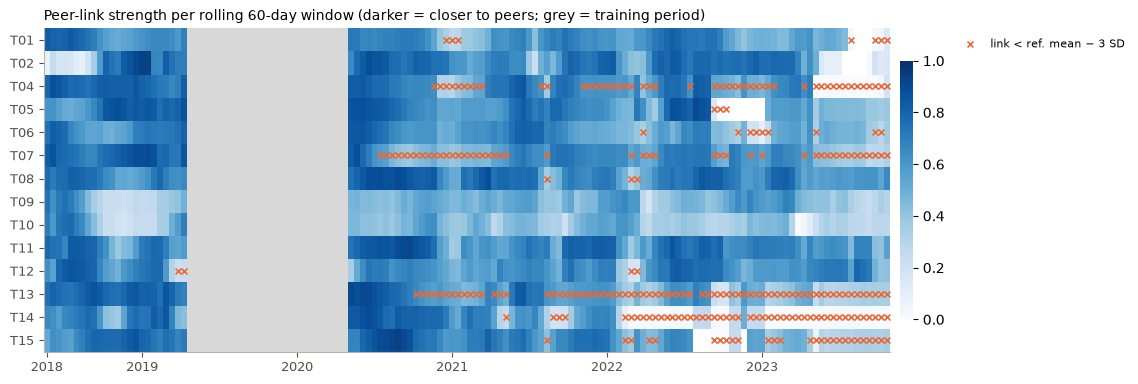

268 weak-link windows


,windows,first,last
turbine,,,
T01,7,2020-12-25,2023-10-27
T04,49,2020-11-27,2023-10-27
T05,3,2022-09-16,2022-10-14
T06,9,2022-04-01,2023-10-13
T07,46,2020-07-24,2023-10-27
T08,3,2021-08-20,2022-03-18
T12,4,2019-04-05,2022-03-18
T13,72,2020-10-16,2023-10-27
T14,48,2021-05-14,2023-10-27


In [28]:
win_starts = pd.date_range(start, all_days[-1] - pd.Timedelta(days=60), freq="14D")
V = []
for ws in win_starts:
    sl = own_daily.loc[(slice(None), slice(ws, ws + pd.Timedelta(days=59))), :]
    V.append(sl.groupby(level="turbine_id").mean().reindex(TURBINES).to_numpy())
V = np.array(V)   # windows x turbines x targets
dists = np.sqrt(np.nansum((V[:, :, None, :] - V[:, None, :, :]) ** 2, -1))
in_ref = np.array([day_period.get(ws + pd.Timedelta(days=59), "none") == "reference" for ws in win_starts])
sig = np.median(dists[in_ref][:, ~np.eye(len(TURBINES), dtype=bool)])
Wt = np.exp(-dists ** 2 / (2 * sig ** 2))
link = np.stack([Wt[:, i, [TURBINES.index(p) for p in peers[t]]].mean(1) for i, t in enumerate(TURBINES)], 1)
link[np.isnan(V).all(-1)] = np.nan
ref_mu, ref_sd = np.nanmean(link[in_ref], 0), np.nanstd(link[in_ref], 0)
weak = link < ref_mu - 3 * ref_sd
in_train = np.array([day_period.get(ws + pd.Timedelta(days=30), "none") == "training" for ws in win_starts])
link[in_train] = np.nan
weak[in_train] = False

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.imshow(np.where(in_train, 1.0, np.nan)[None, :].repeat(len(TURBINES), 0), aspect="auto", cmap="Greys",
          vmin=0, vmax=4, interpolation="none")
im = ax.imshow(link.T, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="none")
wi, ti = np.nonzero(weak)
ax.scatter(wi, ti, marker="x", color=PALETTE[1], s=18, lw=1.2, label="link < ref. mean − 3 SD")
ax.set_yticks(range(len(TURBINES)), [TL[t] for t in TURBINES])
yi = [i for i, ws in enumerate(win_starts) if i == 0 or ws.year != win_starts[i - 1].year]
ax.set_xticks(yi, [win_starts[i].year for i in yi])
ax.legend(loc="upper left", bbox_to_anchor=(1.07, 1), frameon=False, fontsize=8)
ax.set_title("Peer-link strength per rolling 60-day window (darker = closer to peers; grey = training period)", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

weak_df = pd.DataFrame({"turbine": [TL[TURBINES[i]] for i in ti], "window start": win_starts[wi]})
print(f"{len(weak_df)} weak-link windows")
weak_df.groupby("turbine").agg(windows=("window start", "size"), first=("window start", "min"), last=("window start", "max"))

## Step 6: Injected-fault validation

Synthetic faults are injected into **healthy test-period data** on one bearing temperature (`INJECT_TARGET`, gearbox axle bearing 1):

- (a) **step** offsets and (b) **ramps** (linear over `RAMP_DAYS`, then held), of each size in `INJECT_SIZES`, at each onset in `ONSETS`, into one turbine at a time
- (c) a **farm-wide step** applied to every turbine at once

The bearing temperature is not a model input, so a fault of +s °C raises its residual by exactly s. The injection is therefore added to the residual (for peer residuals, after the peer median is taken). Detectors compared:

| detector | data | alarm rule |
|---|---|---|
| per-turbine SPE | residuals, PCA fitted on the turbine's own reference data | SPE above a calibrated limit, `N_CONSECUTIVE` in a row |
| whole-farm SPE | residuals, farm PCA from Step 3(b) | same |
| group SPE | residuals, PCA fitted on the turbine's frozen group | same |
| own-residual CUSUM | daily binned own residuals, all 8 targets | any target alarms (calibrated h) |
| peer-residual CUSUM | daily binned peer residuals, all 8 targets | same |

**Equal-cost comparison.** Each detector's threshold is calibrated on the reference period to `TARGET_FA` false alarms per turbine-month: the SPE limit as a percentile of reference SPE, the CUSUM h on a grid. Uncalibrated, the detectors differ mostly in how often they alarm, not in how well they detect.

**Metrics.**
- **Detection**: the first alarm at or after onset, within `HORIZON_DAYS`, that does **not** occur in the same detector's un-injected run. Alarms that would have happened anyway don't count.
- **Delay**: from onset to that alarm. Daily detectors add one day, since a day's value is only known at its end.
- **False alarms**: alarm onsets per turbine-month on un-injected **test** data (calibration used reference data). The test period may contain real faults, so this is an upper bound.

In [29]:
test_h = healthy & (period == "test") & res_ok
mon_turbine = {t: PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(resid[ref_h & res_ok & (tid == t)])
               for t in TURBINES}
mon_group = {}
for gid in set(group_of.values()):
    members = [t for t in TURBINES if group_of[t] == gid]
    mon_group[gid] = PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(
        resid[ref_h & res_ok & np.isin(tid, members)])
MONITOR = {"per-turbine SPE": lambda t: mon_turbine[t], "whole-farm SPE": lambda t: pca_res,
           "group SPE": lambda t: mon_group[group_of[t]]}
SPE_DETS, CUSUM_DETS = list(MONITOR), ["own-residual CUSUM", "peer-residual CUSUM"]
DETECTORS = SPE_DETS + CUSUM_DETS
yi_col = TARGETS.index(INJECT_TARGET)

def arrays(mask):
    rows = {t: np.flatnonzero(mask & (tid == t)) for t in TURBINES}
    X = {t: resid.iloc[r].to_numpy(float) for t, r in rows.items()}
    tm = {t: scada["time_stamp"].iloc[r].to_numpy() for t, r in rows.items()}
    grp_ = {t: contiguous_groups(tm[t], np.full(len(r), t)) for t, r in rows.items()}
    months_ = {t: len(np.unique(tm[t].astype("datetime64[M]"))) for t in TURBINES}
    return rows, X, tm, grp_, months_

R_rows, R_X, R_time, R_grp, R_months = arrays(ref_h & res_ok)    # reference: calibration
T_rows, T_X, T_time, T_grp, T_months = arrays(test_h)            # test: false alarms and injection

# --- Calibrate SPE limits: smallest percentile of the monitor's reference SPE meeting TARGET_FA on reference data.
R_spe = {det: {t: MONITOR[det](t).statistics(R_X[t])[0] for t in TURBINES} for det in SPE_DETS}
def fit_pool(det, t):
    # The reference SPE distribution the monitor was fitted on (own turbine / whole farm / group).
    if det == "per-turbine SPE":
        return R_spe[det][t]
    members = TURBINES if det == "whole-farm SPE" else [u for u in TURBINES if group_of[u] == group_of[t]]
    return np.concatenate([R_spe[det][u] for u in members])
SPE_LIMIT = {}
for det in SPE_DETS:
    for pct in SPE_PCT_GRID:
        lim = {t: np.percentile(fit_pool(det, t), pct) for t in TURBINES}
        n = sum(alarm_onsets(persistence(R_spe[det][t] > lim[t], N_CONSECUTIVE, R_grp[t]), R_grp[t]).sum() for t in TURBINES)
        if n / sum(R_months.values()) <= TARGET_FA or pct == SPE_PCT_GRID[-1]:
            SPE_LIMIT[det] = (pct, lim)
            break

# --- Calibrate CUSUM h for "any of 8 targets" per turbine on reference days.
test_start = pd.Timestamp(SPLIT["test"][0])
ZD = {"own": own_z, "peer": peer_z}
def cusum_any_days(z_by_target, h):
    days = set()
    for y, z in z_by_target.items():
        days |= set(z.index[cusum(z.to_numpy(), CUSUM_K, h)[0]])
    return days
ref_z = {s: {t: {y: ZD[s].loc[t].loc[start:ref_last, y] for y in TARGETS} for t in TURBINES} for s in ZD}
H_ANY = {}
for s in ZD:
    for h in CAL_GRID:
        n = sum(len(cusum_any_days(ref_z[s][t], h)) for t in TURBINES)
        if n / (ref_months * len(TURBINES)) <= TARGET_FA:
            H_ANY[s] = h
            break
    else:
        H_ANY[s] = CAL_GRID[-1]

cal = pd.DataFrame({det: {"threshold": f"SPE > p{SPE_LIMIT[det][0]} of reference", "N consecutive": N_CONSECUTIVE}
                    for det in SPE_DETS} | {f"{s}-residual CUSUM": {"threshold": f"h = {H_ANY[s]}", "N consecutive": "-"}
                                              for s in ZD}).T
cal

,threshold,N consecutive
per-turbine SPE,SPE > p99.9 of reference,6
whole-farm SPE,SPE > p99.8 of reference,6
group SPE,SPE > p99.9 of reference,6
own-residual CUSUM,h = 26.0,-
peer-residual CUSUM,h = 27.0,-


In [30]:
# Test-period daily series and baseline (un-injected) alarms.
test_z = {s: {t: {y: ZD[s].loc[t].loc[test_start:, y] for y in TARGETS} for t in TURBINES} for s in ZD}
base_other = {(s, t): cusum_any_days({y: z for y, z in test_z[s][t].items() if y != INJECT_TARGET}, H_ANY[s])
              for s in ZD for t in TURBINES}
ref_daily_sd = {s: daily[day_period.reindex(daily.index.get_level_values("day")).to_numpy() == "reference"]
                .groupby(level="turbine_id").std() for s, daily in [("own", own_daily), ("peer", peer_daily)]}

# Daily (day, wind-bin) keys of the test rows, so an injection is aggregated exactly as the residuals were.
T_keys = {t: pd.DataFrame({"day": day[r], "bin": wbin[r]}) for t, r in T_rows.items()}
T_peer_ok = {t: peer_res.iloc[r][INJECT_TARGET].notna().to_numpy() for t, r in T_rows.items()}

def agg_injection(t, inj, peer):
    ok = T_peer_ok[t] if peer else np.ones(len(inj), bool)
    g = T_keys[t][ok].assign(v=inj[ok]).groupby(["day", "bin"])["v"]
    m, c = g.mean(), g.size()
    m[c < MIN_BIN_COUNT] = np.nan
    return m.groupby(level="day").mean()

def spe_alarm(det, t, inj):
    X = T_X[t].copy()
    X[:, yi_col] += inj
    spe, _ = MONITOR[det](t).statistics(X)
    return persistence(spe > SPE_LIMIT[det][1][t], N_CONSECUTIVE, T_grp[t])

def cusum_days(s, t, inj):
    z = test_z[s][t][INJECT_TARGET]
    if inj is not None:
        add = agg_injection(t, inj, peer=(s == "peer")).reindex(z.index).fillna(0).to_numpy()
        z = z + add / ref_daily_sd[s].loc[t, INJECT_TARGET]
    return set(z.index[cusum(z.to_numpy(), CUSUM_K, H_ANY[s])[0]]) | base_other[(s, t)]

BASE = {}
for t in TURBINES:
    for det in SPE_DETS:
        BASE[(det, t)] = spe_alarm(det, t, np.zeros(len(T_X[t])))
    for s in ZD:
        BASE[(f"{s}-residual CUSUM", t)] = cusum_days(s, t, None)

fa_test = {}
for det in DETECTORS:
    if det in SPE_DETS:
        n = sum(alarm_onsets(BASE[(det, t)], T_grp[t]).sum() for t in TURBINES)
    else:
        n = sum(len(BASE[(det, t)]) for t in TURBINES)
    fa_test[det] = n / sum(T_months.values())
print("False alarms per turbine-month on un-injected test data:", {k: round(v, 2) for k, v in fa_test.items()})

False alarms per turbine-month on un-injected test data: {'per-turbine SPE': np.float64(0.38), 'whole-farm SPE': np.float64(0.13), 'group SPE': np.float64(0.08), 'own-residual CUSUM': 1.97, 'peer-residual CUSUM': 2.7}


In [31]:
def injection(t, kind, size, onset):
    dt = (T_time[t] - np.datetime64(onset)) / np.timedelta64(1, "D")
    if kind == "step":
        return np.where(dt >= 0, size, 0.0)
    return np.clip(dt / RAMP_DAYS, 0, 1) * size

def delay_days(first, onset, daily):
    if first is None:
        return None
    d = (first - np.datetime64(onset)) / np.timedelta64(1, "D") + (1 if daily else 0)
    return d if d <= HORIZON_DAYS else None

def detect(t, inj, onset, peer_inj=True):
    # Delay per detector: first alarm >= onset that is absent from the un-injected run.
    out, on = {}, np.datetime64(onset)
    for det in SPE_DETS:
        new = spe_alarm(det, t, inj) & ~BASE[(det, t)]
        times = T_time[t][new]
        times = times[times >= on]
        out[det] = delay_days(times.min() if len(times) else None, onset, False)
    for s in ZD:
        det = f"{s}-residual CUSUM"
        injected = cusum_days(s, t, inj if (s == "own" or peer_inj) else None)
        new = sorted(d for d in injected - BASE[(det, t)] if d >= pd.Timestamp(onset))
        out[det] = delay_days(np.datetime64(new[0]) if new else None, onset, True)
    return out

t0 = time.time()
res_rows = []
for t in TURBINES:
    for onset in ONSETS:
        after = (T_time[t] >= np.datetime64(onset)) & (T_time[t] < np.datetime64(onset) + np.timedelta64(HORIZON_DAYS, "D"))
        if after.sum() < 144 * 20:      # skip onsets without 20 days of healthy data in the horizon (outages)
            continue
        for kind in ["step", "ramp"]:
            for size in INJECT_SIZES:
                d = detect(t, injection(t, kind, size, onset), onset)
                res_rows += [(t, kind, size, onset, det, v) for det, v in d.items()]
res = pd.DataFrame(res_rows, columns=["turbine_id", "kind", "size", "onset", "detector", "delay_days"])
res["detected"] = res["delay_days"].notna()
print(f"{res.groupby(['turbine_id', 'kind', 'size', 'onset']).ngroups} single-turbine scenarios in {time.time() - t0:.0f} s")

# (c) Farm-wide step on every turbine at once. Every turbine and its peers shift by the same amount, so the
# peer residual is unchanged wherever the peer median exists (peer_inj=False); the other detectors see it.
farm_rows = []
for size in INJECT_SIZES:
    for onset in ONSETS:
        for t in TURBINES:
            d = detect(t, injection(t, "step", size, onset), onset, peer_inj=False)
            farm_rows += [(t, size, onset, det, v) for det, v in d.items()]
farm = pd.DataFrame(farm_rows, columns=["turbine_id", "size", "onset", "detector", "delay_days"])
farm["detected"] = farm["delay_days"].notna()

328 single-turbine scenarios in 1034 s


### Summary

In [32]:
summ = (res.groupby(["detector", "kind", "size"])
        .agg(detection_rate=("detected", "mean"), median_delay_days=("delay_days", "median")).reset_index())
table = summ.pivot(index="detector", columns=["kind", "size"], values=["detection_rate", "median_delay_days"])
table = table.reindex(DETECTORS)
farm_rate = farm.groupby("detector")["detected"].mean().reindex(DETECTORS)
fa = fa_test
table.columns = [f"{'rate' if v == 'detection_rate' else 'delay d'} {k} {sz:g}°C" for v, k, sz in table.columns]
table = table[sorted(table.columns, key=lambda c: (c.split()[-2], float(c.split()[-1][:-2]), c.split()[0]))]
summary = pd.concat([pd.Series(fa).reindex(DETECTORS).rename("false alarms / turbine-month (test)"),
                     farm_rate.rename("farm-wide step: share alarming"), table], axis=1)
summary.round(2)

,false alarms / turbine-month (test),farm-wide step: share alarming,delay d ramp 1°C,rate ramp 1°C,delay d ramp 2°C,rate ramp 2°C,delay d ramp 3°C,rate ramp 3°C,delay d ramp 5°C,rate ramp 5°C,delay d step 1°C,rate step 1°C,delay d step 2°C,rate step 2°C,delay d step 3°C,rate step 3°C,delay d step 5°C,rate step 5°C
per-turbine SPE,0.38,0.40,44.35,0.22,34.77,0.32,34.76,0.37,32.44,0.54,32.19,0.24,29.62,0.37,25.14,0.44,25.82,0.61
whole-farm SPE,0.13,0.24,38.30,0.05,63.76,0.15,64.01,0.22,44.35,0.41,38.30,0.05,53.95,0.20,53.95,0.29,35.45,0.46
group SPE,0.08,0.17,38.27,0.05,39.91,0.10,53.92,0.15,44.35,0.22,38.27,0.05,35.44,0.12,39.91,0.20,30.52,0.32
own-residual CUSUM,1.97,0.86,42.00,0.73,34.00,0.85,28.50,0.88,23.50,0.98,30.00,0.78,22.00,0.88,14.00,0.88,9.00,1.00
peer-residual CUSUM,2.70,0.00,27.00,0.59,29.50,0.93,25.00,0.98,18.00,1.00,16.00,0.66,11.00,0.90,8.00,0.98,5.00,1.00


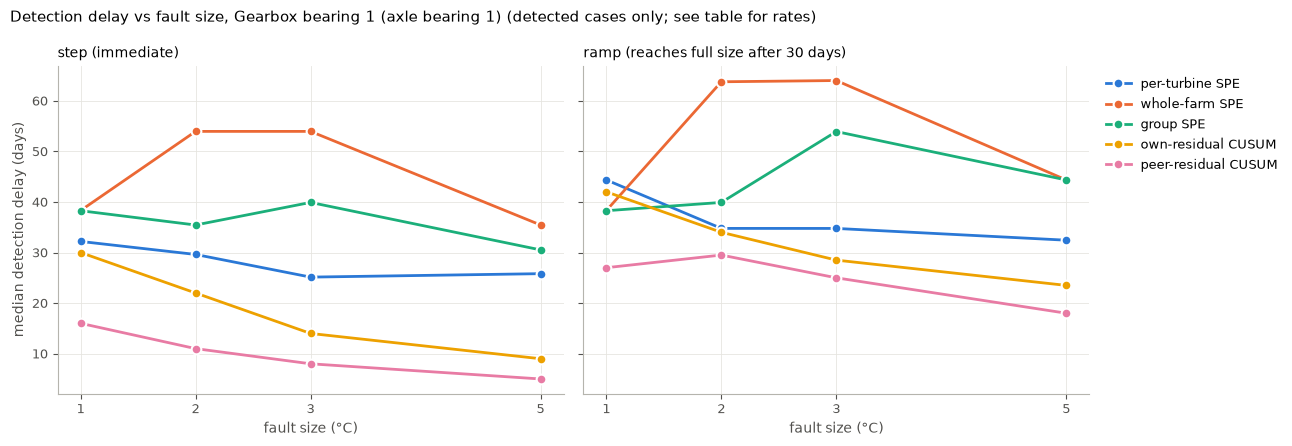

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, kind in zip(axes, ["step", "ramp"]):
    s = summ[summ["kind"] == kind]
    for k, det in enumerate(DETECTORS):
        d = s[s["detector"] == det].sort_values("size")
        ax.plot(d["size"], d["median_delay_days"], color=PALETTE[k], marker="o", ms=7, lw=2, label=det,
                markeredgecolor="white", markeredgewidth=1.5)
    ax.set_xticks(INJECT_SIZES)
    ax.set_xlabel("fault size (°C)", color=MUTED)
    ax.set_title(f"{kind} ({'reaches full size after ' + str(RAMP_DAYS) + ' days' if kind == 'ramp' else 'immediate'})",
                 loc="left", fontsize=10)
    style_ax(ax)
axes[0].set_ylabel("median detection delay (days)", color=MUTED)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
fig.suptitle(f"Detection delay vs fault size, {LBL[INJECT_TARGET]} (detected cases only; see table for rates)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

### Reading the results

All detectors are calibrated to the same false-alarm rate on reference data (`TARGET_FA`), and only alarms caused by the injection count.

- **Daily CUSUM beats 10-minute SPE for slow, single-component drift.** Averaging residuals per day within wind bins removes most of the weather noise, so a shift of 1–2 °C (under one residual SD) builds up in CUSUM within days to weeks. SPE judges each 10-minute sample against a threshold set for 1-in-1000 samples, and needs a large offset to cross it.
- **Peer-residual CUSUM is faster than own-residual CUSUM**, because subtracting the peer median removes the weather and seasonal swings the model misses. That lowers the noise the fault has to stand out from.
- **The farm-wide step is the key contrast.** Own-residual detectors alarm on most turbines; the peer-residual CUSUM alarms on none. Running both tells a farm-wide change (own fires, peer doesn't) from a turbine-specific one (both fire).
- **Per-turbine SPE beats group and whole-farm SPE.** Pooled models must treat between-turbine differences (e.g. T09/T10's cooler gear-oil inlet) as normal, which widens their limits.
- **False alarms rise in the test period**, especially for CUSUM. Some is real (the T14 bearing replacement and other changes in the event log); some is model ageing, since the normal-behaviour models are fitted once on mid-2019 to mid-2020 data. Re-fitting yearly or after confirmed maintenance would bring it down.

All settings (sizes, onsets, ramp length, persistence, false-alarm target) are in the configuration cell.

## Outputs

`data/Penmanshiel/analysis/` holds `residuals.parquet` (residuals, all flags, healthy mask and period for every timestamp; also cached under a settings hash) and `groups.parquet` (frozen groups and peers).